# 把机器人学公式变成代码：平面竖直三连杆
**中文自学 Notebook · iPad Carnets 离线版 · NumPy + Matplotlib**

本教程沿用三根连杆 $l_1=0.4,\ l_2=0.3,\ l_3=0.2\,\mathrm m$，从你已经讨论过的空间/刚体旋量出发，一直走到动力学和轨迹控制。所有机器人学算法均在本文件内实现，不调用现代机器人学库、仿真引擎、SciPy、网络服务或其他本地文件。

## 使用方式与兼容性
1. 将 `.ipynb` 保存到 iPad「文件」中，使用 Carnets 打开。选择 Python 3 内核，点击代码单元的运行按钮。
2. 初学时按顺序阅读；**每个代码单元都包含自身所需的导入、参数和基础函数，可在重启内核后单独运行**。为实现这一点，后面会重复少量已学函数。先找单元底部的 `本节实验`；带 `本节公式的实现` 的部分是本节新函数。
3. **参数修改只影响当前单元**。若想把修改延续到下一节，在下一节顶部也修改对应参数。这是独立单元设计的取舍。
4. 图内使用英文和数学符号，正文为中文，避免 iPad 缺少中文绘图字体导致方框。图是静态图片，不依赖 widgets、GUI 或在线 JavaScript。无需安装任何包。
5. 仿真是低维教学规模，默认步长 $0.01\,\mathrm s$、短时长；iPad 上的耗时随设备变化。先运行前半部分，再逐个运行仿真单元。

Carnets 官方项目及开发者说明支持本地离线运行，普通版预装 NumPy、Matplotlib：[官方项目](https://github.com/holzschu/Carnets)、[应用说明](https://apps.apple.com/us/app/carnets-jupyter/id1450994949)。这些链接仅供查阅，运行无需联网。本文件通过桌面 Python 的逐单元独立执行和顺序执行验证；未在实体 iPad 上实测。

## 分四次学习
| 学习批次 | 章节 | 目标 |
|---|---|---|
| 第一次 | 00–09 | 建模、旋量原始定义、伴随、POE |
| 第二次 | 10–15 | 雅可比、真实速度、奇异性、逆运动学 |
| 第三次 | 16–23 | 质心、能量、质量矩阵、完整动力学 |
| 第四次 | 24–30 | 积分、能量、PD、重力补偿、计算力矩 |

每节在理论后给出代码、检查和练习。默认示例均为明确给定的教学模型，并非某台实物机器人的辨识参数。


## 已执行的检查结果
31 个代码单元均通过逐单元独立执行与从头顺序执行，保留了 13 张图和检查输出。桌面运行记录：
- 两种 POE 与几何正运动学的最大误差约 $6\times10^{-16}$。
- 独立 Euler–Lagrange 抽样检查最大误差约 $3.2\times10^{-10}$ N·m。
- 自由运动示例中，RK4 步长从 0.01 s 减至 0.005 s，最大归一化能量漂移由 $3.84\times10^{-5}$ 降至 $2.56\times10^{-6}$。
- 轨迹控制后半段，计算力矩控制三关节 RMSE 约为 0.022°、0.013°、0.014°；这是本模型、本增益和本轨迹下的示例结果。

以上是桌面双精度 Python 运行结果；实体 iPad 的速度与具体包版本可能不同。本文件未在实体 iPad 上实测。


## 00｜先确认环境可运行
只导入 NumPy 和 Matplotlib。Python 标准语法与普通数组即可完成后续算法。角度输入可以用度表示，计算统一用弧度；长度 m、质量 kg、时间 s、力矩 N·m。

下方应显示版本号与一张正弦曲线。若看不到图，先重新运行该单元；在 Carnets 中也可另加 `%matplotlib inline`，它不是本教程的必要依赖。


NumPy: 2.3.5
Matplotlib: 3.10.9


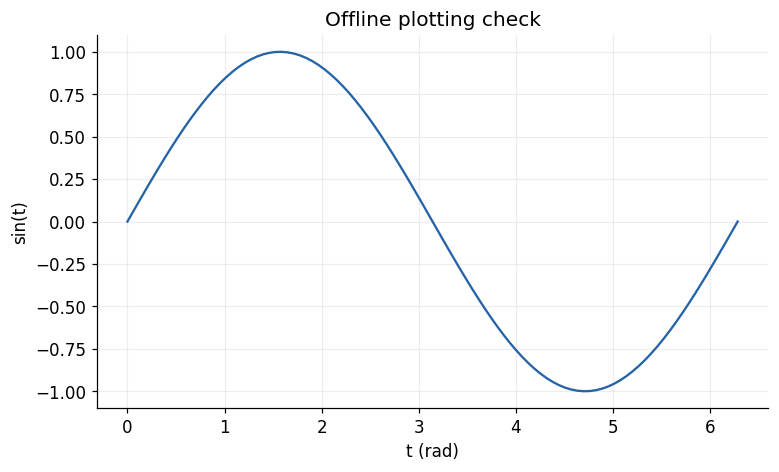

In [1]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

# ===== 本节实验：优先阅读并修改这里 =====
print('NumPy:', np.__version__)
print('Matplotlib:', plt.matplotlib.__version__)
t = np.linspace(0, 2*np.pi, 100)
fig, ax = plt.subplots()
ax.plot(t, np.sin(t), color=colors[0])
ax.set(xlabel='t (rad)', ylabel='sin(t)', title='Offline plotting check')
fig.tight_layout(); plt.show()


## 01｜建模：关节角与连杆绝对朝向
空间系 $\{s\}$ 固定在基座：$x$ 向右、$y$ 向上、$z$ 朝向观察者。三根连杆在竖直 $xy$ 平面内运动，三个转轴均沿 $+z$，正角逆时针。$q_i$ 是相邻连杆间的**相对角**，不是第 $i$ 根杆的绝对朝向。

$$\alpha_i=\sum_{k=1}^i q_k,\qquad p_i=p_{i-1}+l_i[\cos\alpha_i,\ \sin\alpha_i,\ 0]^T.$$

$p_0=0$ 为基座；本节下标 $p_i$ 表示第 $i$ 根杆的远端，后文 POE 中的 `p0` 专指**所选刚体系零位原点**，留意语境。默认末端刚体系原点位于第三根杆末端，零位朝向与空间系一致。

**检查**：$q=0$ 时末端为 $(0.9,0,0)$。**练习**：只修改第二关节角，观察第三根杆为何也移动。


relative q (deg): [ 30. -45.  60.]
absolute alpha (deg): [ 30. -15.  45.]
end point (m): [0.777609 0.263776 0.      ]


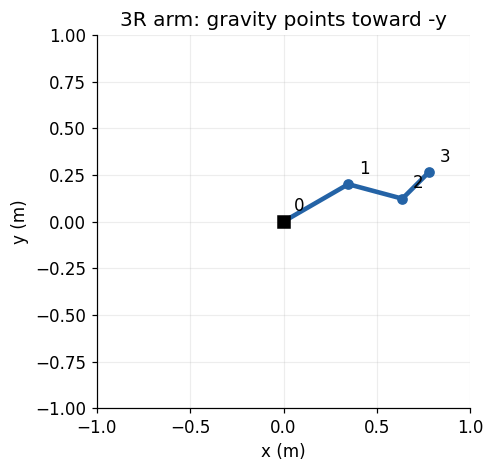

In [2]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

# ===== 本节公式的实现 =====
def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

# ===== 本节实验：优先阅读并修改这里 =====
q = q_demo.copy()
P = joint_points(q)
print('relative q (deg):', np.rad2deg(q))
print('absolute alpha (deg):', np.rad2deg(np.cumsum(q)))
print('end point (m):', P[-1])
assert np.allclose(joint_points(np.zeros(3))[-1], [0.9, 0, 0])
fig, ax = plt.subplots()
draw_arm(ax, q)
for i, p in enumerate(P): ax.annotate(str(i), p[:2], xytext=(7, 7), textcoords='offset points')
ax.set_title('3R arm: gravity points toward -y')
fig.tight_layout(); plt.show()


## 02｜齐次变换、反对称矩阵与伴随

齐次变换把旋转矩阵与原点位置组合起来：

$$
T_{sb} =
\begin{bmatrix}
R & p \\
0_{1\times 3} & 1
\end{bmatrix}.
$$

其中 $R\in\mathbb{R}^{3\times 3}$，$p=p_{sb}\in\mathbb{R}^{3}$ 是刚体系原点在空间系中的位置。$T_{sb}$ 把刚体系坐标转换到空间系：

$$
{}^s p_P = R\,{}^b p_P + p.
$$

反对称矩阵用方括号表示，其作用等价于叉乘：

$$
\left[\omega\right]x = \omega\times x.
$$

本教程统一采用**角速度在前**的六维旋量：

$$
V = \begin{bmatrix}\omega \\ v\end{bmatrix},
\qquad
\left[V\right] =
\begin{bmatrix}
\left[\omega\right] & v \\
0_{1\times 3} & 0
\end{bmatrix}.
$$

这里 $V$ 是 $6\times 1$ 向量，$\left[V\right]$ 是 $4\times 4$ 矩阵；$\left[\omega\right]$ 是 $3\times 3$ 反对称矩阵。代码中的 `hat(V)`、`skew(w)` 分别实现这两种矩阵表示。

逆变换与伴随矩阵分别为：

$$
T_{sb}^{-1} =
\begin{bmatrix}
R^T & -R^T p \\
0_{1\times 3} & 1
\end{bmatrix}.
$$

$$
\operatorname{Ad}_{T_{sb}} =
\begin{bmatrix}
R & 0_{3\times 3} \\
\left[p\right]R & R
\end{bmatrix}.
$$

伴随矩阵的四个分块均为 $3\times 3$，整体为 $6\times 6$；左下分块的乘法顺序是 $\left[p\right]R$。

**检查**：叉乘、变换逆和伴随的矩阵共轭形式。**练习**：故意交换 $\left[p\right]R$ 的乘法次序，观察哪项检查不通过。


In [3]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

# ===== 本节公式的实现 =====
def skew(w):
    wx, wy, wz = w
    return np.array([[0., -wz, wy], [wz, 0., -wx], [-wy, wx, 0.]])

def vee3(W):
    return np.array([W[2, 1], W[0, 2], W[1, 0]])

def hat(V):
    X = np.zeros((4, 4))
    X[:3, :3] = skew(V[:3])
    X[:3, 3] = V[3:]
    return X

def vee(X):
    return np.r_[vee3(X[:3, :3]), X[:3, 3]]

def invT(T):
    R, p = T[:3, :3], T[:3, 3]
    Ti = np.eye(4)
    Ti[:3, :3], Ti[:3, 3] = R.T, -R.T @ p
    return Ti

def Ad(T):
    R, p = T[:3, :3], T[:3, 3]
    A = np.zeros((6, 6))
    A[:3, :3] = R
    A[3:, :3], A[3:, 3:] = skew(p) @ R, R
    return A

# ===== 本节实验：优先阅读并修改这里 =====
w, x = np.array([0.2, -0.4, 0.7]), np.array([1., 2., 3.])
T, V = fk_geom(q_demo), np.array([0., 0., 0.5, 0.2, -0.1, 0.3])
assert np.allclose(skew(w) @ x, np.cross(w, x))
assert np.allclose(T @ invT(T), np.eye(4))
assert np.allclose(hat(Ad(T) @ V), T @ hat(V) @ invT(T))
print('叉乘、逆变换、伴随共轭：PASS')
print('T_sb =\n', T)


叉乘、逆变换、伴随共轭：PASS
T_sb =
 [[ 0.707107 -0.707107  0.        0.777609]
 [ 0.707107  0.707107  0.        0.263776]
 [ 0.        0.        1.        0.      ]
 [ 0.        0.        0.        1.      ]]


## 03｜从原始定义理解空间旋量与刚体旋量
对光滑刚体运动 $T(t)=[R(t),p(t)]$：
$$[V_s]=\dot T T^{-1},\quad \omega_s^\wedge=\dot RR^T,
\quad v_s=\dot p-\omega_s\times p;$$
$$[V_b]=T^{-1}\dot T,\quad \omega_b^\wedge=R^T\dot R,
\quad v_b=R^T\dot p.$$

因此 $v_b$ 是**所选刚体系原点的真实速度在刚体系中的表达**；$v_s$ 一般不等于原点速度 $\dot p$。对刚体上任意固定点 $P$，其真实速度满足
$$ {}^sv_P=\omega_s\times{}^sp_P+v_s,\qquad
{}^bv_P=\omega_b\times{}^bp_P+v_b.$$

注意：刚体固定点的 ${}^bp_P$ 是常量，故 $\frac{d}{dt}({}^bp_P)=0$；这**不表示真实速度** ${}^bv_P$ 为零。旋转坐标系下“坐标导数”和“真实速度的坐标表达”是两件事。

代码用独立几何正运动学与中心差分直接计算 $\dot T$，不借助雅可比。**练习**：把角速度和末端平移速度分别改成零，检查公式的简化。


In [4]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

def skew(w):
    wx, wy, wz = w
    return np.array([[0., -wz, wy], [wz, 0., -wx], [-wy, wx, 0.]])

def vee3(W):
    return np.array([W[2, 1], W[0, 2], W[1, 0]])

def hat(V):
    X = np.zeros((4, 4))
    X[:3, :3] = skew(V[:3])
    X[:3, 3] = V[3:]
    return X

def vee(X):
    return np.r_[vee3(X[:3, :3]), X[:3, 3]]

def invT(T):
    R, p = T[:3, :3], T[:3, 3]
    Ti = np.eye(4)
    Ti[:3, :3], Ti[:3, 3] = R.T, -R.T @ p
    return Ti

def Ad(T):
    R, p = T[:3, :3], T[:3, 3]
    A = np.zeros((6, 6))
    A[:3, :3] = R
    A[3:, :3], A[3:, 3:] = skew(p) @ R, R
    return A

# ===== 本节实验：优先阅读并修改这里 =====
q, dq = q_demo.copy(), np.array([0.4, -0.2, 0.3])
h = 1e-6
T = fk_geom(q)
dT = (fk_geom(q+h*dq)-fk_geom(q-h*dq))/(2*h)
Vs, Vb = vee(dT @ invT(T)), vee(invT(T) @ dT)
p, R, dp = T[:3, 3], T[:3, :3], dT[:3, 3]
print('Vs=[ws;vs]:', Vs)
print('Vb=[wb;vb]:', Vb)
print('real origin velocity dp:', dp)
assert np.allclose(dp, np.cross(Vs[:3], p)+Vs[3:], atol=1e-8)
assert np.allclose(Vb[3:], R.T @ dp, atol=1e-8)
assert np.allclose(Vs, Ad(T) @ Vb, atol=1e-8)
# 固定在刚体中的一个点，坐标本身不变，但真实速度一般不为零。
pb = np.array([0.08, 0.02, 0.])
vP_b = Vb[3:] + np.cross(Vb[:3], pb)
def point_s(qq):
    TT = fk_geom(qq)
    return TT[:3, :3] @ pb + TT[:3, 3]
vP_fd = (point_s(q+h*dq)-point_s(q-h*dq))/(2*h)
assert np.allclose(R @ vP_b, vP_fd, atol=1e-8)
print('fixed body point: coordinate derivative=0, real vP_b=', vP_b)


Vs=[ws;vs]: [ 0.        0.        0.5      -0.003294 -0.121574  0.      ]
Vb=[wb;vb]: [0.       0.       0.5      0.093373 0.284548 0.      ]
real origin velocity dp: [-0.135182  0.26723   0.      ]
fixed body point: coordinate derivative=0, real vP_b= [0.083373 0.324548 0.      ]


## 04｜零位空间轴 $S_i$：从速度定义到轴几何
令机器人在零位，只让关节 $i$ 以 $1\,\mathrm{rad/s}$ 转动。$r_i^s$ 是**从空间原点指向该转轴上一点的位置向量**，$p_0$ 是零位末端原点。
$$\dot p_i^s=\omega_i^s\times(p_0-r_i^s),\qquad
v_i^s=\dot p_i^s-\omega_i^s\times p_0=-\omega_i^s\times r_i^s.$$
$$S_i=[\omega_i^s;v_i^s].$$

默认 $r_1^s=(0,0,0),r_2^s=(0.4,0,0),r_3^s=(0.7,0,0)$，故三列 $v_i^s$ 的 $y$ 分量为 $0,-0.4,-0.7$。`Slist` 是**零位常量轴**；运动中的瞬时轴稍后由空间雅可比给出。

**练习**：在同一条轴上把 $r_i$ 加上 $(0,0,2)$，为什么 $S_i$ 不变？


In [5]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

def skew(w):
    wx, wy, wz = w
    return np.array([[0., -wz, wy], [wz, 0., -wx], [-wy, wx, 0.]])

def vee3(W):
    return np.array([W[2, 1], W[0, 2], W[1, 0]])

def hat(V):
    X = np.zeros((4, 4))
    X[:3, :3] = skew(V[:3])
    X[:3, 3] = V[3:]
    return X

def vee(X):
    return np.r_[vee3(X[:3, :3]), X[:3, 3]]

def invT(T):
    R, p = T[:3, :3], T[:3, 3]
    Ti = np.eye(4)
    Ti[:3, :3], Ti[:3, 3] = R.T, -R.T @ p
    return Ti

def Ad(T):
    R, p = T[:3, :3], T[:3, 3]
    A = np.zeros((6, 6))
    A[:3, :3] = R
    A[3:, :3], A[3:, 3:] = skew(p) @ R, R
    return A

# ===== 本节实验：优先阅读并修改这里 =====
p0 = np.array([np.sum(l), 0., 0.])
ri = np.array([[0., 0., 0.], [l[0], 0., 0.], [l[0]+l[1], 0., 0.]])
wi = np.array([0., 0., 1.])
S_original, S_geometry = [], []
for i in range(3):
    dpi = np.cross(wi, p0-ri[i])
    vi = dpi-np.cross(wi, p0)
    S_original.append(np.r_[wi, vi])
    S_geometry.append(np.r_[wi, -np.cross(wi, ri[i])])
    h, ei = 1e-6, np.eye(3)[i]
    dTi = (fk_geom(h*ei)-fk_geom(-h*ei))/(2*h)
    assert np.allclose(vee(dTi @ invT(fk_geom(np.zeros(3)))), S_original[-1], atol=1e-8)
Slist = np.column_stack(S_geometry)
assert np.allclose(Slist, np.column_stack(S_original))
print('Slist =\n', Slist)


Slist =
 [[ 0.   0.   0. ]
 [ 0.   0.   0. ]
 [ 1.   1.   1. ]
 [-0.  -0.  -0. ]
 [-0.  -0.4 -0.7]
 [-0.  -0.  -0. ]]


## 05｜零位刚体轴 $B_i$：允许 $R_0\ne I$
$$\omega_i^b=R_0^T\omega_i^s,\quad r_i^b=R_0^T(r_i^s-p_0),$$
$$v_i^b=R_0^T\dot p_i^s=-\omega_i^b\times r_i^b,\qquad B_i=[\omega_i^b;v_i^b].$$

这里 $r_i^b$ 是**从所选刚体系原点指向转轴点**的向量，方向不要取反。默认 $\phi_0=0$，三列 $v_i^b$ 的 $y$ 分量为 $0.9,0.5,0.2$。把 $\phi_0$ 改为 $30^\circ$ 只是重新选择末端坐标系方向，不改变实体杆的零位形状。

**练习**：把 `phi0` 改为 0 和 90°，比较 `Blist`；不要把它理解成机器人实际关节转了相同角度。


In [6]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def skew(w):
    wx, wy, wz = w
    return np.array([[0., -wz, wy], [wz, 0., -wx], [-wy, wx, 0.]])

def vee3(W):
    return np.array([W[2, 1], W[0, 2], W[1, 0]])

def hat(V):
    X = np.zeros((4, 4))
    X[:3, :3] = skew(V[:3])
    X[:3, 3] = V[3:]
    return X

def vee(X):
    return np.r_[vee3(X[:3, :3]), X[:3, 3]]

def invT(T):
    R, p = T[:3, :3], T[:3, 3]
    Ti = np.eye(4)
    Ti[:3, :3], Ti[:3, 3] = R.T, -R.T @ p
    return Ti

def Ad(T):
    R, p = T[:3, :3], T[:3, 3]
    A = np.zeros((6, 6))
    A[:3, :3] = R
    A[3:, :3], A[3:, 3:] = skew(p) @ R, R
    return A

# ===== 本节实验：优先阅读并修改这里 =====
phi0 = np.deg2rad(30.)
c, s = np.cos(phi0), np.sin(phi0)
R0 = np.array([[c,-s,0.], [s,c,0.], [0.,0.,1.]])
p0 = np.array([np.sum(l), 0., 0.])
ri_s = np.array([[0.,0.,0.], [l[0],0.,0.], [l[0]+l[1],0.,0.]])
wi_s = np.array([0.,0.,1.])
Blist = []
for r in ri_s:
    wi_b = R0.T @ wi_s
    ri_b = R0.T @ (r-p0)
    dpi_s = np.cross(wi_s, p0-r)
    vi_b = R0.T @ dpi_s
    assert np.allclose(vi_b, -np.cross(wi_b, ri_b))
    Blist.append(np.r_[wi_b, vi_b])
print('phi0=30 deg: Blist =\n', np.column_stack(Blist))
# 将刚体系原点放在关节3轴上，该轴对应的 vb=0。
p0_new = ri_s[2]
vb3_new = R0.T @ np.cross(wi_s, p0_new-ri_s[2])
assert np.allclose(vb3_new, 0)
print('origin on joint3: vb3 =', vb3_new)


phi0=30 deg: Blist =
 [[0.       0.       0.      ]
 [0.       0.       0.      ]
 [1.       1.       1.      ]
 [0.45     0.25     0.1     ]
 [0.779423 0.433013 0.173205]
 [0.       0.       0.      ]]
origin on joint3: vb3 = [0. 0. 0.]


## 06｜伴随转换：同一运动，两种坐标表达
原始定义给出 $[V_s]=T[V_b]T^{-1}$，因此
$$V_s=\operatorname{Ad}_TV_b,\qquad B_i=\operatorname{Ad}_{M^{-1}}S_i.$$

这里 $M=T(0)$ 是零位末端变换。`Slist` 和 `Blist` 都是零位定义的常量；任意时刻的 $V_s,V_b$ 则要用当前 $T(q)$ 转换，不能一直用 $M$。

**检查**：伴随、共轭与直接轴几何在非零 `phi0` 下完全一致。


In [7]:
# 本单元可独立运行。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def skew(w):
    wx, wy, wz = w
    return np.array([[0., -wz, wy], [wz, 0., -wx], [-wy, wx, 0.]])

def vee3(W):
    return np.array([W[2, 1], W[0, 2], W[1, 0]])

def hat(V):
    X = np.zeros((4, 4))
    X[:3, :3] = skew(V[:3])
    X[:3, 3] = V[3:]
    return X

def vee(X):
    return np.r_[vee3(X[:3, :3]), X[:3, 3]]

def invT(T):
    R, p = T[:3, :3], T[:3, 3]
    Ti = np.eye(4)
    Ti[:3, :3], Ti[:3, 3] = R.T, -R.T @ p
    return Ti

def Ad(T):
    R, p = T[:3, :3], T[:3, 3]
    A = np.zeros((6, 6))
    A[:3, :3] = R
    A[3:, :3], A[3:, 3:] = skew(p) @ R, R
    return A

def home_axes(phi0=0.0, p0=None):
    if p0 is None: p0 = np.array([np.sum(l), 0., 0.])
    c, s = np.cos(phi0), np.sin(phi0)
    M = np.eye(4)
    M[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    M[:3, 3] = p0
    ri = np.array([[0., 0., 0.], [l[0], 0., 0.], [l[0]+l[1], 0., 0.]])
    wi = np.array([0., 0., 1.])
    Slist = np.column_stack([np.r_[wi, -np.cross(wi, r)] for r in ri])
    Blist = Ad(invT(M)) @ Slist
    return M, Slist, Blist

# ===== 本节实验 =====
M, Slist, Blist = home_axes(phi0=np.deg2rad(30.))
assert np.allclose(Blist, Ad(invT(M)) @ Slist)
for i in range(3):
    assert np.allclose(hat(Blist[:, i]), invT(M) @ hat(Slist[:, i]) @ M)
print('Slist =\n', Slist)
print('Blist =\n', Blist)
print('伴随与矩阵共轭：PASS')


Slist =
 [[ 0.   0.   0. ]
 [ 0.   0.   0. ]
 [ 1.   1.   1. ]
 [-0.  -0.  -0. ]
 [-0.  -0.4 -0.7]
 [-0.  -0.  -0. ]]
Blist =
 [[0.       0.       0.      ]
 [0.       0.       0.      ]
 [1.       1.       1.      ]
 [0.45     0.25     0.1     ]
 [0.779423 0.433013 0.173205]
 [0.       0.       0.      ]]
伴随与矩阵共轭：PASS


## 07｜把单轴旋转写成矩阵指数
对于 $\|\omega\|=1$ 的转动轴，记 $W=[\omega]$：
$$e^{W\theta}=I+\sin\theta W+(1-\cos\theta)W^2,$$
$$e^{[S]\theta}=\begin{bmatrix}e^{W\theta}&G(\theta)v\\0&1\end{bmatrix},\qquad
G(\theta)=I\theta+(1-\cos\theta)W+(\theta-\sin\theta)W^2.$$

纯移动轴 $\omega=0$ 时，旋转为 $I$，平移为 $v\theta$。代码中的 `sinc` 与小角度级数只是减小数值抵消，不改变公式。本函数的转动轴必须单位化，关节角单独放在 `theta` 中。

**检查**：轴上的点保持不动；正角再负角恢复原位。**练习**：取 $\theta=10^{-10}$，观察结果是否仍有限。


In [8]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def skew(w):
    wx, wy, wz = w
    return np.array([[0., -wz, wy], [wz, 0., -wx], [-wy, wx, 0.]])

def vee3(W):
    return np.array([W[2, 1], W[0, 2], W[1, 0]])

def hat(V):
    X = np.zeros((4, 4))
    X[:3, :3] = skew(V[:3])
    X[:3, 3] = V[3:]
    return X

def vee(X):
    return np.r_[vee3(X[:3, :3]), X[:3, 3]]

def invT(T):
    R, p = T[:3, :3], T[:3, 3]
    Ti = np.eye(4)
    Ti[:3, :3], Ti[:3, 3] = R.T, -R.T @ p
    return Ti

def Ad(T):
    R, p = T[:3, :3], T[:3, 3]
    A = np.zeros((6, 6))
    A[:3, :3] = R
    A[3:, :3], A[3:, 3:] = skew(p) @ R, R
    return A

def home_axes(phi0=0.0, p0=None):
    if p0 is None: p0 = np.array([np.sum(l), 0., 0.])
    c, s = np.cos(phi0), np.sin(phi0)
    M = np.eye(4)
    M[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    M[:3, 3] = p0
    ri = np.array([[0., 0., 0.], [l[0], 0., 0.], [l[0]+l[1], 0., 0.]])
    wi = np.array([0., 0., 1.])
    Slist = np.column_stack([np.r_[wi, -np.cross(wi, r)] for r in ri])
    Blist = Ad(invT(M)) @ Slist
    return M, Slist, Blist

# ===== 本节公式的实现 =====
def exp_twist(S, theta):
    """单位转动轴或纯移动轴的 SE(3) 指数；无需 scipy.linalg.expm。"""
    w, v = S[:3], S[3:]
    T = np.eye(4)
    wn = np.linalg.norm(w)
    if wn < 1e-14:
        T[:3, 3] = v * theta
        return T
    if not np.isclose(wn, 1.0):
        raise ValueError('本教学函数要求转动轴的 ||w||=1')
    W = skew(w)
    # sinc 写法在 theta 很小时也稳定；np.sinc(x)=sin(pi*x)/(pi*x)。
    a = theta * np.sinc(theta/np.pi)
    b = 0.5*theta**2 * np.sinc(theta/(2*np.pi))**2
    c = theta**3/6 * (1-theta**2/20+theta**4/840) if abs(theta)<1e-4 else theta-np.sin(theta)
    T[:3, :3] = np.eye(3) + a*W + b*(W @ W)
    G = theta*np.eye(3) + b*W + c*(W @ W)
    T[:3, 3] = G @ v
    return T

# ===== 本节实验：优先阅读并修改这里 =====
_, Slist, _ = home_axes()
S, theta = Slist[:, 1], 0.6
T = exp_twist(S, theta)
r_axis = np.array([l[0], 0., 0., 1.])
assert np.allclose(T @ r_axis, r_axis)
assert np.allclose(T @ exp_twist(S, -theta), np.eye(4))
assert np.allclose(T[:3,:3].T @ T[:3,:3], np.eye(3))
assert np.isclose(np.linalg.det(T[:3,:3]), 1.)
assert np.all(np.isfinite(exp_twist(S, 1e-10)))
print('exp([S2] theta) =\n', T)


exp([S2] theta) =
 [[ 0.825336 -0.564642  0.        0.069866]
 [ 0.564642  0.825336  0.       -0.225857]
 [ 0.        0.        1.        0.      ]
 [ 0.        0.        0.        1.      ]]


## 08｜空间 POE 与刚体 POE 正运动学
$$T(q)=e^{[S_1]q_1}e^{[S_2]q_2}e^{[S_3]q_3}M
=M e^{[B_1]q_1}e^{[B_2]q_2}e^{[B_3]q_3}.$$

两种乘积的关节次序都是 1、2、3；区别是 $M$ 放在哪里，以及用哪套常量轴。矩阵乘法不能交换顺序。

我们再用第 01 节三角函数几何结果作为独立参考，随机抽样比较。**练习**：交换空间 POE 中第 1、2 个指数，检查误差为什么出现。


In [9]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

def skew(w):
    wx, wy, wz = w
    return np.array([[0., -wz, wy], [wz, 0., -wx], [-wy, wx, 0.]])

def vee3(W):
    return np.array([W[2, 1], W[0, 2], W[1, 0]])

def hat(V):
    X = np.zeros((4, 4))
    X[:3, :3] = skew(V[:3])
    X[:3, 3] = V[3:]
    return X

def vee(X):
    return np.r_[vee3(X[:3, :3]), X[:3, 3]]

def invT(T):
    R, p = T[:3, :3], T[:3, 3]
    Ti = np.eye(4)
    Ti[:3, :3], Ti[:3, 3] = R.T, -R.T @ p
    return Ti

def Ad(T):
    R, p = T[:3, :3], T[:3, 3]
    A = np.zeros((6, 6))
    A[:3, :3] = R
    A[3:, :3], A[3:, 3:] = skew(p) @ R, R
    return A

def home_axes(phi0=0.0, p0=None):
    if p0 is None: p0 = np.array([np.sum(l), 0., 0.])
    c, s = np.cos(phi0), np.sin(phi0)
    M = np.eye(4)
    M[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    M[:3, 3] = p0
    ri = np.array([[0., 0., 0.], [l[0], 0., 0.], [l[0]+l[1], 0., 0.]])
    wi = np.array([0., 0., 1.])
    Slist = np.column_stack([np.r_[wi, -np.cross(wi, r)] for r in ri])
    Blist = Ad(invT(M)) @ Slist
    return M, Slist, Blist

def exp_twist(S, theta):
    """单位转动轴或纯移动轴的 SE(3) 指数；无需 scipy.linalg.expm。"""
    w, v = S[:3], S[3:]
    T = np.eye(4)
    wn = np.linalg.norm(w)
    if wn < 1e-14:
        T[:3, 3] = v * theta
        return T
    if not np.isclose(wn, 1.0):
        raise ValueError('本教学函数要求转动轴的 ||w||=1')
    W = skew(w)
    # sinc 写法在 theta 很小时也稳定；np.sinc(x)=sin(pi*x)/(pi*x)。
    a = theta * np.sinc(theta/np.pi)
    b = 0.5*theta**2 * np.sinc(theta/(2*np.pi))**2
    c = theta**3/6 * (1-theta**2/20+theta**4/840) if abs(theta)<1e-4 else theta-np.sin(theta)
    T[:3, :3] = np.eye(3) + a*W + b*(W @ W)
    G = theta*np.eye(3) + b*W + c*(W @ W)
    T[:3, 3] = G @ v
    return T

# ===== 本节公式的实现 =====
def fk_space(q, phi0=0.0, p0=None):
    M, Slist, _ = home_axes(phi0, p0)
    T = np.eye(4)
    for i in range(3): T = T @ exp_twist(Slist[:, i], q[i])
    return T @ M

def fk_body(q, phi0=0.0, p0=None):
    M, _, Blist = home_axes(phi0, p0)
    T = M.copy()
    for i in range(3): T = T @ exp_twist(Blist[:, i], q[i])
    return T

# ===== 本节实验：优先阅读并修改这里 =====
rng = np.random.default_rng(7)
errors = []
for q in rng.uniform(-1.5, 1.5, size=(30, 3)):
    for phi0 in [0., 0.4]:
        Ts, Tb, Tg = fk_space(q, phi0), fk_body(q, phi0), fk_geom(q, phi0)
        errors.append(max(np.linalg.norm(Ts-Tb), np.linalg.norm(Ts-Tg)))
assert max(errors) < 1e-10
print('30 configurations × 2 frame orientations: max error =', max(errors))
print('T(q_demo) =\n', fk_space(q_demo))


30 configurations × 2 frame orientations: max error = 5.967448757360216e-16
T(q_demo) =
 [[ 0.707107 -0.707107  0.        0.777609]
 [ 0.707107  0.707107  0.        0.263776]
 [ 0.        0.        1.        0.      ]
 [ 0.        0.        0.        1.      ]]


## 09｜更换刚体系原点：同时修正几何验证
把零位刚体系原点移到第三关节轴 $p_0'=(l_1+l_2,0,0)$，并设零位方向 $R_0'$。新变换 $T'$ 描述这个**新坐标系**，不能再把它的平移与原末端位置直接比较。

原末端在新刚体系中的固定坐标为
$$r_{tip}^{b'}=R_0'^T([l_1+l_2+l_3,0,0]^T-p_0'),\qquad
p_{tip}^s=R' r_{tip}^{b'}+p'.$$

第三关节单独旋转时，新原点静止，所以 $B_3'$ 的线速度为零；原末端仍然运动。这里附着坐标系选在第三根杆近端，仍随第三根杆转动。

**练习**：只令 $q_3$ 改变，分别打印新原点位置和重建的真实末端位置。


B3_new = [ 0.  0.  1. -0.  0.  0.]


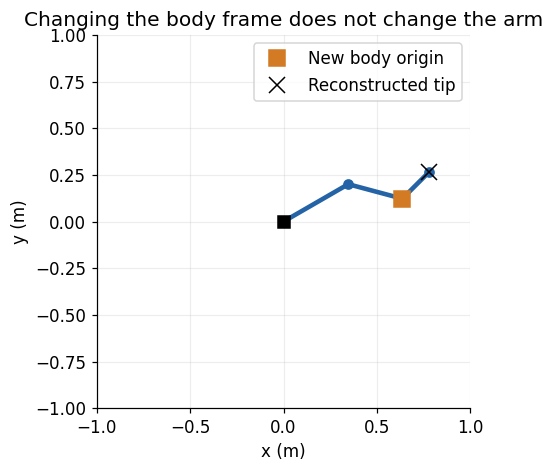

In [10]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def skew(w):
    wx, wy, wz = w
    return np.array([[0., -wz, wy], [wz, 0., -wx], [-wy, wx, 0.]])

def vee3(W):
    return np.array([W[2, 1], W[0, 2], W[1, 0]])

def hat(V):
    X = np.zeros((4, 4))
    X[:3, :3] = skew(V[:3])
    X[:3, 3] = V[3:]
    return X

def vee(X):
    return np.r_[vee3(X[:3, :3]), X[:3, 3]]

def invT(T):
    R, p = T[:3, :3], T[:3, 3]
    Ti = np.eye(4)
    Ti[:3, :3], Ti[:3, 3] = R.T, -R.T @ p
    return Ti

def Ad(T):
    R, p = T[:3, :3], T[:3, 3]
    A = np.zeros((6, 6))
    A[:3, :3] = R
    A[3:, :3], A[3:, 3:] = skew(p) @ R, R
    return A

def home_axes(phi0=0.0, p0=None):
    if p0 is None: p0 = np.array([np.sum(l), 0., 0.])
    c, s = np.cos(phi0), np.sin(phi0)
    M = np.eye(4)
    M[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    M[:3, 3] = p0
    ri = np.array([[0., 0., 0.], [l[0], 0., 0.], [l[0]+l[1], 0., 0.]])
    wi = np.array([0., 0., 1.])
    Slist = np.column_stack([np.r_[wi, -np.cross(wi, r)] for r in ri])
    Blist = Ad(invT(M)) @ Slist
    return M, Slist, Blist

def exp_twist(S, theta):
    """单位转动轴或纯移动轴的 SE(3) 指数；无需 scipy.linalg.expm。"""
    w, v = S[:3], S[3:]
    T = np.eye(4)
    wn = np.linalg.norm(w)
    if wn < 1e-14:
        T[:3, 3] = v * theta
        return T
    if not np.isclose(wn, 1.0):
        raise ValueError('本教学函数要求转动轴的 ||w||=1')
    W = skew(w)
    # sinc 写法在 theta 很小时也稳定；np.sinc(x)=sin(pi*x)/(pi*x)。
    a = theta * np.sinc(theta/np.pi)
    b = 0.5*theta**2 * np.sinc(theta/(2*np.pi))**2
    c = theta**3/6 * (1-theta**2/20+theta**4/840) if abs(theta)<1e-4 else theta-np.sin(theta)
    T[:3, :3] = np.eye(3) + a*W + b*(W @ W)
    G = theta*np.eye(3) + b*W + c*(W @ W)
    T[:3, 3] = G @ v
    return T

def fk_space(q, phi0=0.0, p0=None):
    M, Slist, _ = home_axes(phi0, p0)
    T = np.eye(4)
    for i in range(3): T = T @ exp_twist(Slist[:, i], q[i])
    return T @ M

def fk_body(q, phi0=0.0, p0=None):
    M, _, Blist = home_axes(phi0, p0)
    T = M.copy()
    for i in range(3): T = T @ exp_twist(Blist[:, i], q[i])
    return T

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

# ===== 本节实验：优先阅读并修改这里 =====
phi0 = np.deg2rad(30.)
p0_new = np.array([l[0]+l[1], 0., 0.])
Mnew, _, Bnew = home_axes(phi0, p0_new)
Tnew = fk_body(q_demo, phi0, p0_new)
rtip_b = Mnew[:3,:3].T @ (np.array([np.sum(l),0.,0.])-p0_new)
ptip = Tnew[:3,:3] @ rtip_b + Tnew[:3,3]
assert np.allclose(Bnew[3:,2], 0.)
assert np.allclose(Tnew, fk_space(q_demo, phi0, p0_new))
assert np.allclose(ptip, joint_points(q_demo)[-1])
fig, ax = plt.subplots()
draw_arm(ax, q_demo)
ax.plot(*Tnew[:2,3], 's', color=colors[1], ms=10, label='New body origin')
ax.plot(*ptip[:2], 'x', color='black', ms=10, label='Reconstructed tip')
ax.legend(); ax.set_title('Changing the body frame does not change the arm')
fig.tight_layout(); plt.show()
print('B3_new =', Bnew[:,2])


## 10｜空间雅可比：逐列搬运零位轴
$$V_s=J_s(q)\dot q,\qquad
J_{s,i}=\operatorname{Ad}_{e^{[S_1]q_1}\cdots e^{[S_{i-1}]q_{i-1}}}S_i.$$

第一列没有前序关节，因此 $J_{s,1}=S_1$。第 $i$ 列只依赖前面的关节，表达“当前构型下只给关节 $i$ 单位角速度时，整个末端刚体的空间旋量”。

代码维护 `Tprev`，先计算当前列再乘当前关节指数。用 $\dot T T^{-1}$ 的数值结果验证，不靠另一个雅可比函数自证。


In [11]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def skew(w):
    wx, wy, wz = w
    return np.array([[0., -wz, wy], [wz, 0., -wx], [-wy, wx, 0.]])

def vee3(W):
    return np.array([W[2, 1], W[0, 2], W[1, 0]])

def hat(V):
    X = np.zeros((4, 4))
    X[:3, :3] = skew(V[:3])
    X[:3, 3] = V[3:]
    return X

def vee(X):
    return np.r_[vee3(X[:3, :3]), X[:3, 3]]

def invT(T):
    R, p = T[:3, :3], T[:3, 3]
    Ti = np.eye(4)
    Ti[:3, :3], Ti[:3, 3] = R.T, -R.T @ p
    return Ti

def Ad(T):
    R, p = T[:3, :3], T[:3, 3]
    A = np.zeros((6, 6))
    A[:3, :3] = R
    A[3:, :3], A[3:, 3:] = skew(p) @ R, R
    return A

def home_axes(phi0=0.0, p0=None):
    if p0 is None: p0 = np.array([np.sum(l), 0., 0.])
    c, s = np.cos(phi0), np.sin(phi0)
    M = np.eye(4)
    M[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    M[:3, 3] = p0
    ri = np.array([[0., 0., 0.], [l[0], 0., 0.], [l[0]+l[1], 0., 0.]])
    wi = np.array([0., 0., 1.])
    Slist = np.column_stack([np.r_[wi, -np.cross(wi, r)] for r in ri])
    Blist = Ad(invT(M)) @ Slist
    return M, Slist, Blist

def exp_twist(S, theta):
    """单位转动轴或纯移动轴的 SE(3) 指数；无需 scipy.linalg.expm。"""
    w, v = S[:3], S[3:]
    T = np.eye(4)
    wn = np.linalg.norm(w)
    if wn < 1e-14:
        T[:3, 3] = v * theta
        return T
    if not np.isclose(wn, 1.0):
        raise ValueError('本教学函数要求转动轴的 ||w||=1')
    W = skew(w)
    # sinc 写法在 theta 很小时也稳定；np.sinc(x)=sin(pi*x)/(pi*x)。
    a = theta * np.sinc(theta/np.pi)
    b = 0.5*theta**2 * np.sinc(theta/(2*np.pi))**2
    c = theta**3/6 * (1-theta**2/20+theta**4/840) if abs(theta)<1e-4 else theta-np.sin(theta)
    T[:3, :3] = np.eye(3) + a*W + b*(W @ W)
    G = theta*np.eye(3) + b*W + c*(W @ W)
    T[:3, 3] = G @ v
    return T

def fk_space(q, phi0=0.0, p0=None):
    M, Slist, _ = home_axes(phi0, p0)
    T = np.eye(4)
    for i in range(3): T = T @ exp_twist(Slist[:, i], q[i])
    return T @ M

def fk_body(q, phi0=0.0, p0=None):
    M, _, Blist = home_axes(phi0, p0)
    T = M.copy()
    for i in range(3): T = T @ exp_twist(Blist[:, i], q[i])
    return T

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

# ===== 本节公式的实现 =====
def jac_space(q):
    _, Slist, _ = home_axes()
    Js, Tprev = np.zeros((6, 3)), np.eye(4)
    for i in range(3):
        Js[:, i] = Ad(Tprev) @ Slist[:, i]
        Tprev = Tprev @ exp_twist(Slist[:, i], q[i])
    return Js

# ===== 本节实验：优先阅读并修改这里 =====
q, dq, h = q_demo.copy(), np.array([0.4, -0.2, 0.3]), 1e-6
Js = jac_space(q)
T = fk_geom(q)
dT = (fk_geom(q+h*dq)-fk_geom(q-h*dq))/(2*h)
Vs_fd = vee(dT @ invT(T))
assert np.allclose(Js @ dq, Vs_fd, atol=1e-8)
print('Js =\n', Js)
print('Js @ dq =', Js @ dq)
print('definition residual =', np.linalg.norm(Js @ dq-Vs_fd))


Js =
 [[ 0.        0.        0.      ]
 [ 0.        0.        0.      ]
 [ 1.        1.        1.      ]
 [ 0.        0.2       0.122354]
 [ 0.       -0.34641  -0.636188]
 [ 0.        0.        0.      ]]
Js @ dq = [ 0.        0.        0.5      -0.003294 -0.121574  0.      ]
definition residual = 1.1602766221888838e-10


## 11｜刚体雅可比：从后往前构造
$$V_b=J_b(q)\dot q,\qquad
J_{b,i}=\operatorname{Ad}_{e^{-[B_3]q_3}\cdots e^{-[B_{i+1}]q_{i+1}}}B_i.$$

最后一列 $J_{b,3}=B_3$。逆序指数的顺序不可颠倒。例如 $J_{b,1}=\operatorname{Ad}_{e^{-[B_3]q_3}e^{-[B_2]q_2}}B_1$。

$$J_b=\operatorname{Ad}_{T(q)^{-1}}J_s.$$

**检查**：直接逆序构造、当前位姿伴随、$T^{-1}\dot T$ 三条路径一致，且允许非零末端坐标系朝向。


In [12]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def skew(w):
    wx, wy, wz = w
    return np.array([[0., -wz, wy], [wz, 0., -wx], [-wy, wx, 0.]])

def vee3(W):
    return np.array([W[2, 1], W[0, 2], W[1, 0]])

def hat(V):
    X = np.zeros((4, 4))
    X[:3, :3] = skew(V[:3])
    X[:3, 3] = V[3:]
    return X

def vee(X):
    return np.r_[vee3(X[:3, :3]), X[:3, 3]]

def invT(T):
    R, p = T[:3, :3], T[:3, 3]
    Ti = np.eye(4)
    Ti[:3, :3], Ti[:3, 3] = R.T, -R.T @ p
    return Ti

def Ad(T):
    R, p = T[:3, :3], T[:3, 3]
    A = np.zeros((6, 6))
    A[:3, :3] = R
    A[3:, :3], A[3:, 3:] = skew(p) @ R, R
    return A

def home_axes(phi0=0.0, p0=None):
    if p0 is None: p0 = np.array([np.sum(l), 0., 0.])
    c, s = np.cos(phi0), np.sin(phi0)
    M = np.eye(4)
    M[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    M[:3, 3] = p0
    ri = np.array([[0., 0., 0.], [l[0], 0., 0.], [l[0]+l[1], 0., 0.]])
    wi = np.array([0., 0., 1.])
    Slist = np.column_stack([np.r_[wi, -np.cross(wi, r)] for r in ri])
    Blist = Ad(invT(M)) @ Slist
    return M, Slist, Blist

def exp_twist(S, theta):
    """单位转动轴或纯移动轴的 SE(3) 指数；无需 scipy.linalg.expm。"""
    w, v = S[:3], S[3:]
    T = np.eye(4)
    wn = np.linalg.norm(w)
    if wn < 1e-14:
        T[:3, 3] = v * theta
        return T
    if not np.isclose(wn, 1.0):
        raise ValueError('本教学函数要求转动轴的 ||w||=1')
    W = skew(w)
    # sinc 写法在 theta 很小时也稳定；np.sinc(x)=sin(pi*x)/(pi*x)。
    a = theta * np.sinc(theta/np.pi)
    b = 0.5*theta**2 * np.sinc(theta/(2*np.pi))**2
    c = theta**3/6 * (1-theta**2/20+theta**4/840) if abs(theta)<1e-4 else theta-np.sin(theta)
    T[:3, :3] = np.eye(3) + a*W + b*(W @ W)
    G = theta*np.eye(3) + b*W + c*(W @ W)
    T[:3, 3] = G @ v
    return T

def fk_space(q, phi0=0.0, p0=None):
    M, Slist, _ = home_axes(phi0, p0)
    T = np.eye(4)
    for i in range(3): T = T @ exp_twist(Slist[:, i], q[i])
    return T @ M

def fk_body(q, phi0=0.0, p0=None):
    M, _, Blist = home_axes(phi0, p0)
    T = M.copy()
    for i in range(3): T = T @ exp_twist(Blist[:, i], q[i])
    return T

def jac_space(q):
    _, Slist, _ = home_axes()
    Js, Tprev = np.zeros((6, 3)), np.eye(4)
    for i in range(3):
        Js[:, i] = Ad(Tprev) @ Slist[:, i]
        Tprev = Tprev @ exp_twist(Slist[:, i], q[i])
    return Js

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

# ===== 本节公式的实现 =====
def jac_body(q, phi0=0.0, p0=None):
    _, _, Blist = home_axes(phi0, p0)
    Jb, Ttail = np.zeros((6, 3)), np.eye(4)
    for i in range(2, -1, -1):
        Jb[:, i] = Ad(Ttail) @ Blist[:, i]
        Ttail = Ttail @ exp_twist(Blist[:, i], -q[i])
    return Jb

# ===== 本节实验：优先阅读并修改这里 =====
q, dq, h, phi0 = q_demo.copy(), np.array([0.4,-0.2,0.3]), 1e-6, 0.4
T = fk_geom(q, phi0)
Jb = jac_body(q, phi0)
dT = (fk_geom(q+h*dq, phi0)-fk_geom(q-h*dq, phi0))/(2*h)
assert np.allclose(Jb, Ad(invT(T)) @ jac_space(q), atol=1e-10)
assert np.allclose(Jb @ dq, vee(invT(T) @ dT), atol=1e-8)
print('Jb =\n', Jb)
print('body velocity residual =', np.linalg.norm(Jb @ dq-vee(invT(T) @ dT)))


Jb =
 [[0.       0.       0.      ]
 [0.       0.       0.      ]
 [1.       1.       1.      ]
 [0.62141  0.375595 0.077884]
 [0.536753 0.221197 0.184212]
 [0.       0.       0.      ]]
body velocity residual = 8.683497245918241e-11


## 12｜末端真实速度：$J_s$ 下半部分不能直接拿来用
设 $p$ 是当前末端原点的空间位置：
$$\dot p=\omega_s\times p+v_s
=\underbrace{\left(-[p]J_s^\omega+J_s^v\right)}_{J_p}\dot q
=R\,J_b^v\dot q.$$

默认刚体系原点就是末端，所以 $J_b^v\dot q$ 是末端真实速度在刚体系中的表达。$J_p$ 是空间系下的点速度雅可比，与 $J_s$ 的线速度块含义不同。

若换过刚体系原点，对原末端要加上 $\omega_b\times r_{tip}^b$。本单元重新使用默认末端原点。

**练习**：只给第一关节角速度，此时 $J_s^v$ 第一列是零，但末端显然沿圆弧运动。用打印结果解释原因。


real tip velocity (m/s): [-0.135182  0.26723   0.      ]
space twist linear block: [-0.003294 -0.121574  0.      ]
finite-difference velocity: [-0.135182  0.26723   0.      ]


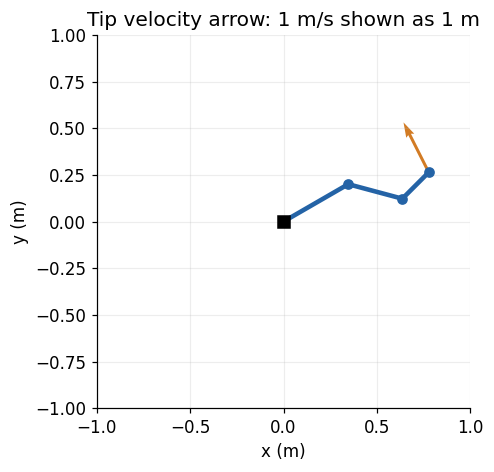

In [13]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def skew(w):
    wx, wy, wz = w
    return np.array([[0., -wz, wy], [wz, 0., -wx], [-wy, wx, 0.]])

def vee3(W):
    return np.array([W[2, 1], W[0, 2], W[1, 0]])

def hat(V):
    X = np.zeros((4, 4))
    X[:3, :3] = skew(V[:3])
    X[:3, 3] = V[3:]
    return X

def vee(X):
    return np.r_[vee3(X[:3, :3]), X[:3, 3]]

def invT(T):
    R, p = T[:3, :3], T[:3, 3]
    Ti = np.eye(4)
    Ti[:3, :3], Ti[:3, 3] = R.T, -R.T @ p
    return Ti

def Ad(T):
    R, p = T[:3, :3], T[:3, 3]
    A = np.zeros((6, 6))
    A[:3, :3] = R
    A[3:, :3], A[3:, 3:] = skew(p) @ R, R
    return A

def home_axes(phi0=0.0, p0=None):
    if p0 is None: p0 = np.array([np.sum(l), 0., 0.])
    c, s = np.cos(phi0), np.sin(phi0)
    M = np.eye(4)
    M[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    M[:3, 3] = p0
    ri = np.array([[0., 0., 0.], [l[0], 0., 0.], [l[0]+l[1], 0., 0.]])
    wi = np.array([0., 0., 1.])
    Slist = np.column_stack([np.r_[wi, -np.cross(wi, r)] for r in ri])
    Blist = Ad(invT(M)) @ Slist
    return M, Slist, Blist

def exp_twist(S, theta):
    """单位转动轴或纯移动轴的 SE(3) 指数；无需 scipy.linalg.expm。"""
    w, v = S[:3], S[3:]
    T = np.eye(4)
    wn = np.linalg.norm(w)
    if wn < 1e-14:
        T[:3, 3] = v * theta
        return T
    if not np.isclose(wn, 1.0):
        raise ValueError('本教学函数要求转动轴的 ||w||=1')
    W = skew(w)
    # sinc 写法在 theta 很小时也稳定；np.sinc(x)=sin(pi*x)/(pi*x)。
    a = theta * np.sinc(theta/np.pi)
    b = 0.5*theta**2 * np.sinc(theta/(2*np.pi))**2
    c = theta**3/6 * (1-theta**2/20+theta**4/840) if abs(theta)<1e-4 else theta-np.sin(theta)
    T[:3, :3] = np.eye(3) + a*W + b*(W @ W)
    G = theta*np.eye(3) + b*W + c*(W @ W)
    T[:3, 3] = G @ v
    return T

def fk_space(q, phi0=0.0, p0=None):
    M, Slist, _ = home_axes(phi0, p0)
    T = np.eye(4)
    for i in range(3): T = T @ exp_twist(Slist[:, i], q[i])
    return T @ M

def fk_body(q, phi0=0.0, p0=None):
    M, _, Blist = home_axes(phi0, p0)
    T = M.copy()
    for i in range(3): T = T @ exp_twist(Blist[:, i], q[i])
    return T

def jac_body(q, phi0=0.0, p0=None):
    _, _, Blist = home_axes(phi0, p0)
    Jb, Ttail = np.zeros((6, 3)), np.eye(4)
    for i in range(2, -1, -1):
        Jb[:, i] = Ad(Ttail) @ Blist[:, i]
        Ttail = Ttail @ exp_twist(Blist[:, i], -q[i])
    return Jb

def jac_space(q):
    _, Slist, _ = home_axes()
    Js, Tprev = np.zeros((6, 3)), np.eye(4)
    for i in range(3):
        Js[:, i] = Ad(Tprev) @ Slist[:, i]
        Tprev = Tprev @ exp_twist(Slist[:, i], q[i])
    return Js

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

# ===== 本节公式的实现 =====
def jac_point(q):
    T = fk_space(q)
    p = T[:3, 3]
    Js = jac_space(q)
    # 每列：omega_i × p + v_i；结果是基坐标系下的真实点速度雅可比。
    Jp = -skew(p) @ Js[:3, :] + Js[3:, :]
    return Jp

# ===== 本节实验：优先阅读并修改这里 =====
q, dq, h = q_demo.copy(), np.array([0.4,-0.2,0.3]), 1e-6
T = fk_geom(q)
v1 = jac_point(q) @ dq
v2 = T[:3,:3] @ (jac_body(q)[3:] @ dq)
v3 = (joint_points(q+h*dq)[-1]-joint_points(q-h*dq)[-1])/(2*h)
assert np.allclose(v1, v2, atol=1e-10)
assert np.allclose(v1, v3, atol=1e-8)
print('real tip velocity (m/s):', v1)
print('space twist linear block:', jac_space(q)[3:] @ dq)
print('finite-difference velocity:', v3)
fig, ax = plt.subplots()
draw_arm(ax, q)
ax.quiver(T[0,3], T[1,3], v1[0], v1[1], angles='xy', scale_units='xy', scale=1,
          color=colors[1], width=0.008)
ax.set_title('Tip velocity arrow: 1 m/s shown as 1 m')
fig.tight_layout(); plt.show()


## 13｜奇异性：根据任务选择雅可比
对平面位置任务 $(x,y)$ 使用 $2\times3$ 的 $J_{xy}$；对平面位姿 $(x,y,\phi)$ 使用 $3\times3$ 的 $J_{xy\phi}$：
$$J_{xy\phi}=\begin{bmatrix}J_p^{x}\\J_p^{y}\\1\;1\;1\end{bmatrix}.$$

所有平面机器人的 $6\times3$ 空间雅可比都有三条受约束的空间方向，判断奇异性时不要要求它具备六维满秩。伸直时位置雅可比秩降为 1，瞬时不能沿杆方向移动。

位置与角度单位不同，分析位姿条件数时应引入长度尺度；本节只对单位一致的 $J_{xy}$ 作奇异值分解。**练习**：比较 $q_2=0$、$q_3\ne0$ 时，位置任务和完整位姿任务的秩是否相同。


In [14]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def skew(w):
    wx, wy, wz = w
    return np.array([[0., -wz, wy], [wz, 0., -wx], [-wy, wx, 0.]])

def vee3(W):
    return np.array([W[2, 1], W[0, 2], W[1, 0]])

def hat(V):
    X = np.zeros((4, 4))
    X[:3, :3] = skew(V[:3])
    X[:3, 3] = V[3:]
    return X

def vee(X):
    return np.r_[vee3(X[:3, :3]), X[:3, 3]]

def invT(T):
    R, p = T[:3, :3], T[:3, 3]
    Ti = np.eye(4)
    Ti[:3, :3], Ti[:3, 3] = R.T, -R.T @ p
    return Ti

def Ad(T):
    R, p = T[:3, :3], T[:3, 3]
    A = np.zeros((6, 6))
    A[:3, :3] = R
    A[3:, :3], A[3:, 3:] = skew(p) @ R, R
    return A

def home_axes(phi0=0.0, p0=None):
    if p0 is None: p0 = np.array([np.sum(l), 0., 0.])
    c, s = np.cos(phi0), np.sin(phi0)
    M = np.eye(4)
    M[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    M[:3, 3] = p0
    ri = np.array([[0., 0., 0.], [l[0], 0., 0.], [l[0]+l[1], 0., 0.]])
    wi = np.array([0., 0., 1.])
    Slist = np.column_stack([np.r_[wi, -np.cross(wi, r)] for r in ri])
    Blist = Ad(invT(M)) @ Slist
    return M, Slist, Blist

def exp_twist(S, theta):
    """单位转动轴或纯移动轴的 SE(3) 指数；无需 scipy.linalg.expm。"""
    w, v = S[:3], S[3:]
    T = np.eye(4)
    wn = np.linalg.norm(w)
    if wn < 1e-14:
        T[:3, 3] = v * theta
        return T
    if not np.isclose(wn, 1.0):
        raise ValueError('本教学函数要求转动轴的 ||w||=1')
    W = skew(w)
    # sinc 写法在 theta 很小时也稳定；np.sinc(x)=sin(pi*x)/(pi*x)。
    a = theta * np.sinc(theta/np.pi)
    b = 0.5*theta**2 * np.sinc(theta/(2*np.pi))**2
    c = theta**3/6 * (1-theta**2/20+theta**4/840) if abs(theta)<1e-4 else theta-np.sin(theta)
    T[:3, :3] = np.eye(3) + a*W + b*(W @ W)
    G = theta*np.eye(3) + b*W + c*(W @ W)
    T[:3, 3] = G @ v
    return T

def fk_space(q, phi0=0.0, p0=None):
    M, Slist, _ = home_axes(phi0, p0)
    T = np.eye(4)
    for i in range(3): T = T @ exp_twist(Slist[:, i], q[i])
    return T @ M

def fk_body(q, phi0=0.0, p0=None):
    M, _, Blist = home_axes(phi0, p0)
    T = M.copy()
    for i in range(3): T = T @ exp_twist(Blist[:, i], q[i])
    return T

def jac_space(q):
    _, Slist, _ = home_axes()
    Js, Tprev = np.zeros((6, 3)), np.eye(4)
    for i in range(3):
        Js[:, i] = Ad(Tprev) @ Slist[:, i]
        Tprev = Tprev @ exp_twist(Slist[:, i], q[i])
    return Js

def jac_point(q):
    T = fk_space(q)
    p = T[:3, 3]
    Js = jac_space(q)
    # 每列：omega_i × p + v_i；结果是基坐标系下的真实点速度雅可比。
    Jp = -skew(p) @ Js[:3, :] + Js[3:, :]
    return Jp

# ===== 本节实验：优先阅读并修改这里 =====
for name, q in [('straight', np.zeros(3)), ('bent', q_demo)]:
    Jxy = jac_point(q)[:2]
    Jpose = np.vstack((Jxy, np.ones(3)))
    sigma = np.linalg.svd(Jxy, compute_uv=False)
    print(name, 'position rank:', np.linalg.matrix_rank(Jxy),
          'pose rank:', np.linalg.matrix_rank(Jpose), 'sigma:', sigma)
assert np.linalg.matrix_rank(jac_point(np.zeros(3))[:2]) == 1
assert np.linalg.matrix_rank(jac_point(q_demo)[:2]) == 2


straight position rank: 1 pose rank: 2 sigma: [1.048809 0.      ]
bent position rank: 2 pose rank: 3 sigma: [0.943755 0.116533]


## 14｜数值逆运动学：阻尼最小二乘
对位置或位姿误差 $e$ 进行局部线性化：$e\approx J\Delta q$。使用
$$\Delta q=\widetilde J^T(\widetilde J\widetilde J^T+\lambda^2I)^{-1}\widetilde e,
\quad \widetilde J=WJ,\quad \widetilde e=We.$$

仅位置任务 $W=I_2$；位姿任务 $W=\operatorname{diag}(1,1,L_{ref})$，把 rad 姿态误差换成 m 尺度。姿态差用 `wrap` 映射到 $[-\pi,\pi)$。代码通过 `solve` 解线性方程，不显式求逆；限制单步关节变化，再做误差下降回溯。

逆解不保证全局收敛，也不唯一。示例没有关节限位、自碰撞与障碍物；阻尼能改善近奇异数值问题，却不能让不可达目标变可达。位置目标即使在总长度圆内，也仍应检查最终残差。

**练习**：换初值，比较不同位置逆解；把目标改为 $(1.2,0)$，应返回失败而非假装成功。


position IK: True q(deg)= [ 46.015392 -65.159745  26.44855 ]
pose IK: True q(deg)= [ 40.000002 -65.000006  50.000004]
unreachable target: False residual(m)= 0.30008713248940466


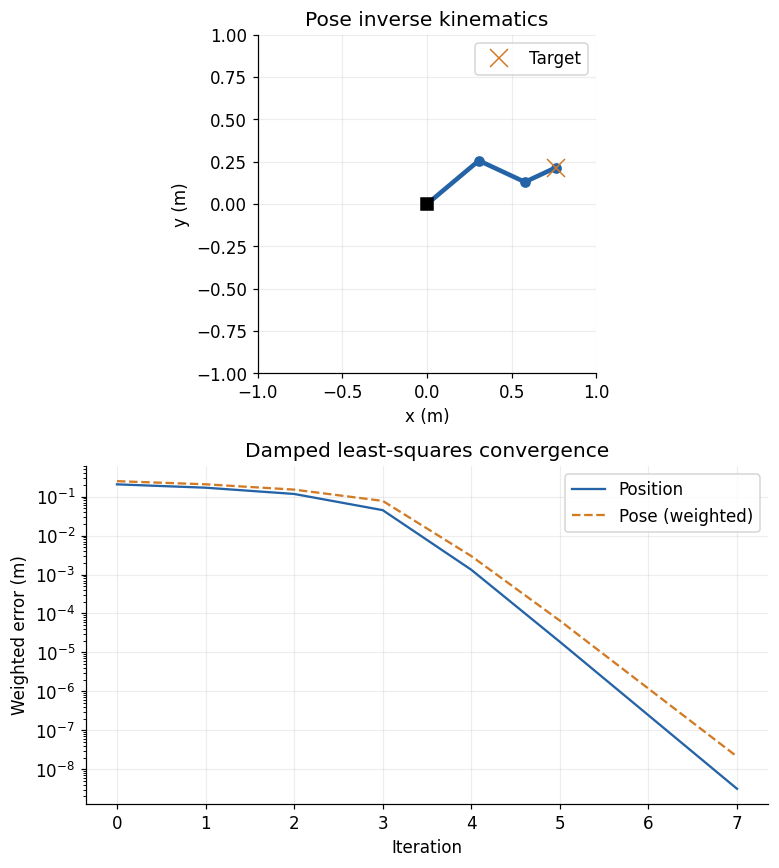

In [15]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

# ===== 本节公式的实现 =====
def wrap(a):
    return (a + np.pi) % (2*np.pi) - np.pi

def jac_planar(q):
    alpha = np.cumsum(q)
    J = np.zeros((3, 3))
    for j in range(3):
        J[0, j] = -np.sum(l[j:]*np.sin(alpha[j:]))
        J[1, j] =  np.sum(l[j:]*np.cos(alpha[j:]))
    J[2, :] = 1.0
    return J

def ik_dls(target, q0, pose=False, max_iter=150, damping=0.02):
    """target=[x,y] 或 [x,y,phi]；无关节限位；返回成功标记和迭代历史。"""
    q = np.array(q0, dtype=float).copy()
    Lref = 0.4  # m/rad，把姿态误差换成可比较的长度尺度
    W = np.diag([1., 1., Lref]) if pose else np.eye(2)
    history = []
    for _ in range(max_iter):
        p = joint_points(q)[-1, :2]
        e = np.r_[target[:2]-p, wrap(target[2]-np.sum(q))] if pose else target[:2]-p
        A = W @ (jac_planar(q) if pose else jac_planar(q)[:2])
        b = W @ e
        history.append(np.linalg.norm(b))
        if np.linalg.norm(e[:2]) < 1e-7 and (not pose or abs(e[2]) < 1e-7):
            return q, True, np.array(history)
        step = A.T @ np.linalg.solve(A @ A.T + damping**2*np.eye(len(b)), b)
        step *= min(1., 0.25/max(np.linalg.norm(step), 1e-15))
        # 回溯，避免本次迭代使加权误差上升。
        accepted = False
        for scale in [1., 0.5, 0.25, 0.125, 0.0625]:
            q_new = q + scale*step
            pn = joint_points(q_new)[-1, :2]
            en = np.r_[target[:2]-pn, wrap(target[2]-np.sum(q_new))] if pose else target[:2]-pn
            if np.linalg.norm(W @ en) < np.linalg.norm(b):
                q, accepted = q_new, True
                break
        if not accepted: break
    return q, False, np.array(history)

# ===== 本节实验：优先阅读并修改这里 =====
q_seed = np.deg2rad([15., -30., 20.])
q_known = np.deg2rad([40., -65., 50.])
target_pose = np.r_[joint_points(q_known)[-1,:2], np.sum(q_known)]
q_pos, ok_pos, hp = ik_dls(target_pose[:2], q_seed, pose=False)
q_pose, ok_pose, hf = ik_dls(target_pose, q_seed, pose=True)
assert ok_pos and ok_pose
assert np.linalg.norm(joint_points(q_pose)[-1,:2]-target_pose[:2]) < 1e-7
assert abs(wrap(np.sum(q_pose)-target_pose[2])) < 1e-7
q_bad, ok_bad, hb = ik_dls(np.array([1.2, 0.]), q_seed)
assert not ok_bad
print('position IK:', ok_pos, 'q(deg)=', np.rad2deg(q_pos))
print('pose IK:', ok_pose, 'q(deg)=', np.rad2deg(q_pose))
print('unreachable target:', ok_bad, 'residual(m)=', hb[-1])
fig, axes = plt.subplots(2, 1, figsize=(7.2, 8.0))
draw_arm(axes[0], q_pose)
axes[0].plot(*target_pose[:2], 'x', color=colors[1], ms=12, label='Target')
axes[0].legend(); axes[0].set_title('Pose inverse kinematics')
axes[1].semilogy(hp, label='Position', color=colors[0])
axes[1].semilogy(hf, '--', label='Pose (weighted)', color=colors[1])
axes[1].set(xlabel='Iteration', ylabel='Weighted error (m)', title='Damped least-squares convergence')
axes[1].legend(); fig.tight_layout(); plt.show()


## 15｜末端受力如何变成关节力矩：虚功检查
从真实点速度 $v=J_p\dot q$ 与功率守恒得到
$$\tau_{ext}=J_p^Tf_s,\qquad \tau_{ext}^T\dot q=f_s^T\dot p.$$

$f_s$ 是**环境施加于机器人末端**的力，单位 N，本节只考虑末端的力、没有末端力偶。完整六维扳手的变换需要同时处理力矩参考点，不能直接把 $J_s^v$ 当作 $J_p$ 来用。

**练习**：令末端受到竖直向下的力，观察哪些关节需要更大的静态支撑力矩。


In [16]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def skew(w):
    wx, wy, wz = w
    return np.array([[0., -wz, wy], [wz, 0., -wx], [-wy, wx, 0.]])

def vee3(W):
    return np.array([W[2, 1], W[0, 2], W[1, 0]])

def hat(V):
    X = np.zeros((4, 4))
    X[:3, :3] = skew(V[:3])
    X[:3, 3] = V[3:]
    return X

def vee(X):
    return np.r_[vee3(X[:3, :3]), X[:3, 3]]

def invT(T):
    R, p = T[:3, :3], T[:3, 3]
    Ti = np.eye(4)
    Ti[:3, :3], Ti[:3, 3] = R.T, -R.T @ p
    return Ti

def Ad(T):
    R, p = T[:3, :3], T[:3, 3]
    A = np.zeros((6, 6))
    A[:3, :3] = R
    A[3:, :3], A[3:, 3:] = skew(p) @ R, R
    return A

def home_axes(phi0=0.0, p0=None):
    if p0 is None: p0 = np.array([np.sum(l), 0., 0.])
    c, s = np.cos(phi0), np.sin(phi0)
    M = np.eye(4)
    M[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    M[:3, 3] = p0
    ri = np.array([[0., 0., 0.], [l[0], 0., 0.], [l[0]+l[1], 0., 0.]])
    wi = np.array([0., 0., 1.])
    Slist = np.column_stack([np.r_[wi, -np.cross(wi, r)] for r in ri])
    Blist = Ad(invT(M)) @ Slist
    return M, Slist, Blist

def exp_twist(S, theta):
    """单位转动轴或纯移动轴的 SE(3) 指数；无需 scipy.linalg.expm。"""
    w, v = S[:3], S[3:]
    T = np.eye(4)
    wn = np.linalg.norm(w)
    if wn < 1e-14:
        T[:3, 3] = v * theta
        return T
    if not np.isclose(wn, 1.0):
        raise ValueError('本教学函数要求转动轴的 ||w||=1')
    W = skew(w)
    # sinc 写法在 theta 很小时也稳定；np.sinc(x)=sin(pi*x)/(pi*x)。
    a = theta * np.sinc(theta/np.pi)
    b = 0.5*theta**2 * np.sinc(theta/(2*np.pi))**2
    c = theta**3/6 * (1-theta**2/20+theta**4/840) if abs(theta)<1e-4 else theta-np.sin(theta)
    T[:3, :3] = np.eye(3) + a*W + b*(W @ W)
    G = theta*np.eye(3) + b*W + c*(W @ W)
    T[:3, 3] = G @ v
    return T

def fk_space(q, phi0=0.0, p0=None):
    M, Slist, _ = home_axes(phi0, p0)
    T = np.eye(4)
    for i in range(3): T = T @ exp_twist(Slist[:, i], q[i])
    return T @ M

def fk_body(q, phi0=0.0, p0=None):
    M, _, Blist = home_axes(phi0, p0)
    T = M.copy()
    for i in range(3): T = T @ exp_twist(Blist[:, i], q[i])
    return T

def jac_space(q):
    _, Slist, _ = home_axes()
    Js, Tprev = np.zeros((6, 3)), np.eye(4)
    for i in range(3):
        Js[:, i] = Ad(Tprev) @ Slist[:, i]
        Tprev = Tprev @ exp_twist(Slist[:, i], q[i])
    return Js

def jac_point(q):
    T = fk_space(q)
    p = T[:3, 3]
    Js = jac_space(q)
    # 每列：omega_i × p + v_i；结果是基坐标系下的真实点速度雅可比。
    Jp = -skew(p) @ Js[:3, :] + Js[3:, :]
    return Jp

# ===== 本节实验：优先阅读并修改这里 =====
q, dq = q_demo.copy(), np.array([0.3, -0.1, 0.2])
f_s = np.array([2., -5., 0.])
Jp = jac_point(q)
tau_ext = Jp.T @ f_s
power_joint, power_tip = tau_ext @ dq, f_s @ (Jp @ dq)
assert np.isclose(power_joint, power_tip)
print('environment joint torque (Nm):', tau_ext)
print('power at joints / tip (W):', power_joint, power_tip)


environment joint torque (Nm): [-4.415598 -2.283547 -0.989949]
power at joints / tip (W): -1.2943145022095475 -1.2943145022095475


## 16｜质心与质心雅可比：动力学从这里开始
假设各杆均匀、刚性，质量为 $m_i$，质心距近端 $l_{ci}=l_i/2$，关于质心垂直平面的惯量 $I_{zi}=m_il_i^2/12$。忽略电机转子、减速器、摩擦、弹性与末端载荷。

$$p_{ci}=p_{i-1}+l_{ci}[\cos\alpha_i,\sin\alpha_i,0]^T.$$
对能影响第 $i$ 根杆的关节 $j\le i$：
$$J_{vi,j}=\hat z\times(p_{ci}-p_{j-1}),\qquad J_{\omega i,j}=\hat z.$$
对 $j>i$ 两列均为零。于是 $v_{ci}=J_{vi}\dot q,\ \omega_i=J_{\omega i}\dot q$。

`Jv[i,:,j]` 表示第 $i$ 根杆关于关节 $j$ 的那一列；Python 从 0 编号，公式从 1 编号。**检查**：各质心三条速度列都用位置差分验证。**练习**：把第三根杆质心移到近端 80% 处，同时明确惯量需要怎样重新设定。


COM positions (m):
 [[0.173205 0.1      0.      ]
 [0.491299 0.161177 0.      ]
 [0.706899 0.193065 0.      ]]
link 2 Jv =
 [[-0.161177  0.038823  0.      ]
 [ 0.491299  0.144889  0.      ]
 [ 0.       -0.        0.      ]]


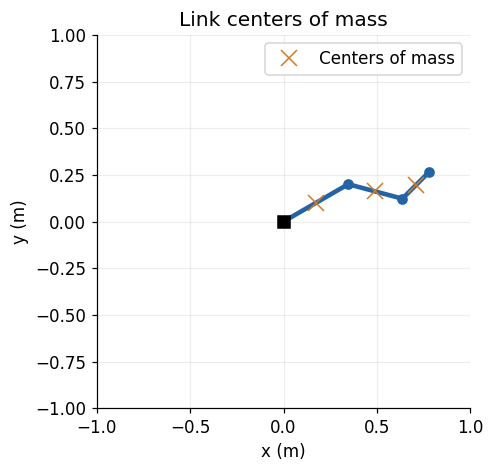

In [17]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

# ===== 本节公式的实现 =====
def com_data(q):
    """pc[i], Jv[i], Jw[i]：第 i 根连杆质心位置及速度雅可比。"""
    P = joint_points(q)
    alpha = np.cumsum(q)
    pc = P[:3] + np.column_stack((lc*np.cos(alpha), lc*np.sin(alpha), np.zeros(3)))
    Jv, Jw = np.zeros((3, 3, 3)), np.zeros((3, 3, 3))
    z = np.array([0., 0., 1.])
    for i in range(3):
        for j in range(i+1):
            Jv[i, :, j] = np.cross(z, pc[i]-P[j])
            Jw[i, :, j] = z
    return pc, Jv, Jw

# ===== 本节实验：优先阅读并修改这里 =====
q, h = q_demo.copy(), 1e-6
pc, Jv, Jw = com_data(q)
for j in range(3):
    e = np.eye(3)[j]*h
    dpc = (com_data(q+e)[0]-com_data(q-e)[0])/(2*h)
    assert np.allclose(Jv[:,:,j], dpc, atol=1e-8)
assert np.allclose(Jv[0,:,1:], 0.)
print('COM positions (m):\n', pc)
print('link 2 Jv =\n', Jv[1])
fig, ax = plt.subplots()
draw_arm(ax, q)
ax.plot(pc[:,0], pc[:,1], 'x', ms=10, color=colors[1], label='Centers of mass')
ax.legend(); ax.set_title('Link centers of mass')
fig.tight_layout(); plt.show()


## 17｜动能、势能与拉格朗日函数
$$K=\frac12\sum_i\left(m_i v_{ci}^Tv_{ci}+I_{zi}\omega_{zi}^2\right),\quad
U=\sum_i m_i g_0 y_{ci},\quad L=K-U.$$

重力沿 $-y$，所以向上抬高质心会增加势能。选择 $y=0$ 作为零势能面，$U$ 可以为负；加任意常数不会改变动力学。这里 $I_{zi}$ 关于质心，不是关于关节；平动部分已经计入质心移动，避免再次用平行轴定理重复计算。

**检查**：$K(q,0)=0$、$K(q,-\dot q)=K(q,\dot q)$，速度加倍动能变为四倍。**练习**：零位仅关节 1 转动，手算各质心速度并比较。


In [18]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

def com_data(q):
    """pc[i], Jv[i], Jw[i]：第 i 根连杆质心位置及速度雅可比。"""
    P = joint_points(q)
    alpha = np.cumsum(q)
    pc = P[:3] + np.column_stack((lc*np.cos(alpha), lc*np.sin(alpha), np.zeros(3)))
    Jv, Jw = np.zeros((3, 3, 3)), np.zeros((3, 3, 3))
    z = np.array([0., 0., 1.])
    for i in range(3):
        for j in range(i+1):
            Jv[i, :, j] = np.cross(z, pc[i]-P[j])
            Jw[i, :, j] = z
    return pc, Jv, Jw

# ===== 本节公式的实现 =====
def kinetic(q, dq):
    _, Jv, Jw = com_data(q)
    K = 0.0
    for i in range(3):
        vc, wc = Jv[i] @ dq, Jw[i] @ dq
        K += 0.5*m[i]*(vc @ vc) + 0.5*Izz[i]*wc[2]**2
    return K

def potential(q):
    pc, _, _ = com_data(q)
    return g0 * (m @ pc[:, 1])

# ===== 本节实验：优先阅读并修改这里 =====
q, dq = q_demo.copy(), np.array([0.4,-0.2,0.3])
K, U = kinetic(q,dq), potential(q)
assert np.isclose(kinetic(q,np.zeros(3)), 0.)
assert np.isclose(kinetic(q,-dq), K)
assert np.isclose(kinetic(q,2*dq), 4*K)
print('K, U, L, E (J):', K, U, K-U, K+U)
print('Izz (kg m^2):', Izz)


K, U, L, E (J): 0.042563491575517476 4.189028156696011 -4.146464665120494 4.231591648271529
Izz (kg m^2): [0.02   0.0075 0.002 ]


## 18｜质量矩阵 $H(q)$：把动能整理成二次型
$$K=\frac12\dot q^T H(q)\dot q,\qquad
H(q)=\sum_i\left(m_iJ_{vi}^TJ_{vi}+I_{zi}J_{\omega zi}^TJ_{\omega zi}\right).$$

用 `H` 表示质量矩阵，以区别零位位姿 `M`。$H$ 的单位为 kg·m²，对称且正定；其非对角项表示惯性耦合。关节运动学奇异并不意味着质量矩阵奇异。

一般三维模型需要 $J_\omega^T R I_bR^T J_\omega$；本模型只绕 $z$ 转动，标量 $I_{zi}$ 足够。**检查**：用独立质心动能路径验证二次型，再随机检查正定性。


H =
 [[0.679041 0.22652  0.040182]
 [0.22652  0.11     0.017   ]
 [0.040182 0.017    0.008   ]]
eigenvalues at q_demo: [0.005179 0.031143 0.760719]
minimum sampled eigenvalue: 0.0023649655621031567


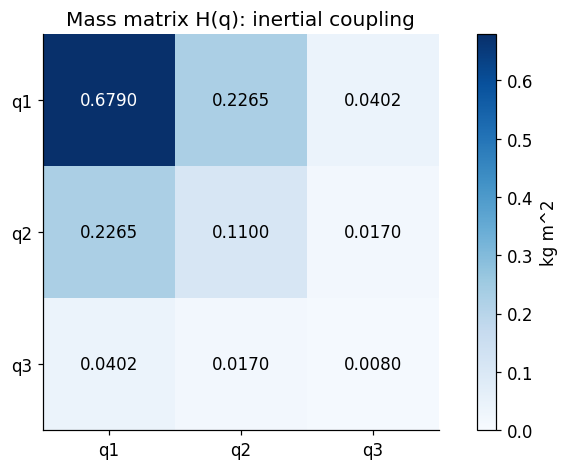

In [19]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

def com_data(q):
    """pc[i], Jv[i], Jw[i]：第 i 根连杆质心位置及速度雅可比。"""
    P = joint_points(q)
    alpha = np.cumsum(q)
    pc = P[:3] + np.column_stack((lc*np.cos(alpha), lc*np.sin(alpha), np.zeros(3)))
    Jv, Jw = np.zeros((3, 3, 3)), np.zeros((3, 3, 3))
    z = np.array([0., 0., 1.])
    for i in range(3):
        for j in range(i+1):
            Jv[i, :, j] = np.cross(z, pc[i]-P[j])
            Jw[i, :, j] = z
    return pc, Jv, Jw

def kinetic(q, dq):
    _, Jv, Jw = com_data(q)
    K = 0.0
    for i in range(3):
        vc, wc = Jv[i] @ dq, Jw[i] @ dq
        K += 0.5*m[i]*(vc @ vc) + 0.5*Izz[i]*wc[2]**2
    return K

def potential(q):
    pc, _, _ = com_data(q)
    return g0 * (m @ pc[:, 1])

# ===== 本节公式的实现 =====
def mass_matrix(q):
    _, Jv, Jw = com_data(q)
    H = np.zeros((3, 3))  # 用 H 区分质量矩阵和零位变换 M
    for i in range(3):
        H += m[i]*(Jv[i].T @ Jv[i]) + Izz[i]*np.outer(Jw[i, 2], Jw[i, 2])
    return H

# ===== 本节实验：优先阅读并修改这里 =====
q, dq = q_demo.copy(), np.array([0.4,-0.2,0.3])
H = mass_matrix(q)
assert np.allclose(H, H.T)
assert np.isclose(0.5*dq @ H @ dq, kinetic(q,dq), atol=1e-12)
rng = np.random.default_rng(18)
eigenvalues = np.array([np.linalg.eigvalsh(mass_matrix(qq)) for qq in rng.uniform(-np.pi,np.pi,(25,3))])
assert eigenvalues.min() > 0.
print('H =\n', H)
print('eigenvalues at q_demo:', np.linalg.eigvalsh(H))
print('minimum sampled eigenvalue:', eigenvalues.min())
fig, ax = plt.subplots()
im = ax.imshow(H, cmap='Blues', vmin=0)
ax.set_xticks(range(3)); ax.set_yticks(range(3))
ax.set_xticklabels(['q1','q2','q3']); ax.set_yticklabels(['q1','q2','q3'])
for i in range(3):
    for j in range(3):
        ax.text(j,i,'%.4f' % H[i,j], ha='center', va='center',
                color='white' if H[i,j] > 0.5*H.max() else 'black')
ax.grid(False); ax.set_title('Mass matrix H(q): inertial coupling')
fig.colorbar(im, ax=ax, label='kg m^2')
fig.tight_layout(); plt.show()


## 19｜重力项：支撑力矩的符号
$$g(q)=\frac{\partial U}{\partial q}=\sum_i m_i g_0 J_{vi}^{y\,T}.$$

动力学约定为 $H\ddot q+c+g=\tau$。因此无驱动力矩时，重力导致的加速度是 $-H^{-1}g$；要静止支撑，则需 $\tau=g(q)$。`gravity(q)` 返回的是方程左侧的重力项，也就是静态补偿力矩，**不是重力本身施加的广义力** $-g$。

零位所有杆水平向右，重力想让杆顺时针落下，因此正向支撑力矩应为正。全部竖直向上时，理想模型中重力力矩为零，但这个平衡是失稳的。

**检查**：势能梯度、质心重力虚功和零位手算支撑力矩。**练习**：把 $q_1=-90^\circ$，其余为零，比较与竖直向上状态的势能和稳定性。


In [20]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

def com_data(q):
    """pc[i], Jv[i], Jw[i]：第 i 根连杆质心位置及速度雅可比。"""
    P = joint_points(q)
    alpha = np.cumsum(q)
    pc = P[:3] + np.column_stack((lc*np.cos(alpha), lc*np.sin(alpha), np.zeros(3)))
    Jv, Jw = np.zeros((3, 3, 3)), np.zeros((3, 3, 3))
    z = np.array([0., 0., 1.])
    for i in range(3):
        for j in range(i+1):
            Jv[i, :, j] = np.cross(z, pc[i]-P[j])
            Jw[i, :, j] = z
    return pc, Jv, Jw

def kinetic(q, dq):
    _, Jv, Jw = com_data(q)
    K = 0.0
    for i in range(3):
        vc, wc = Jv[i] @ dq, Jw[i] @ dq
        K += 0.5*m[i]*(vc @ vc) + 0.5*Izz[i]*wc[2]**2
    return K

def potential(q):
    pc, _, _ = com_data(q)
    return g0 * (m @ pc[:, 1])

def mass_matrix(q):
    _, Jv, Jw = com_data(q)
    H = np.zeros((3, 3))  # 用 H 区分质量矩阵和零位变换 M
    for i in range(3):
        H += m[i]*(Jv[i].T @ Jv[i]) + Izz[i]*np.outer(Jw[i, 2], Jw[i, 2])
    return H

# ===== 本节公式的实现 =====
def gravity(q):
    _, Jv, _ = com_data(q)
    g = np.zeros(3)
    for i in range(3): g += m[i]*g0*Jv[i, 1, :]
    return g

# ===== 本节实验：优先阅读并修改这里 =====
q, h = q_demo.copy(), 1e-6
g = gravity(q)
gradU = np.array([(potential(q+h*e)-potential(q-h*e))/(2*h) for e in np.eye(3)])
assert np.allclose(g, gradU, atol=1e-8)
_, Jv, _ = com_data(q)
Qgravity = sum(Jv[i].T @ np.array([0., -m[i]*g0, 0.]) for i in range(3))
assert np.allclose(Qgravity, -g)
g_home_hand = g0*np.array([m[0]*lc[0]+m[1]*(l[0]+lc[1])+m[2]*(l[0]+l[1]+lc[2]),
                          m[1]*lc[1]+m[2]*(l[1]+lc[2]), m[2]*lc[2]])
assert np.allclose(gravity(np.zeros(3)), g_home_hand)
assert np.linalg.norm(gravity(np.array([np.pi/2,0.,0.]))) < 1e-12
print('g(q_demo), Nm:', g)
print('home support torque, Nm:', g_home_hand)


g(q_demo), Nm: [11.529161  3.543195  0.416203]
home support torque, Nm: [13.0473  3.8259  0.5886]


## 20｜质量矩阵导数：先差分，再用解析导数加速
科氏项需要 $\partial H/\partial q_k$。最容易对应公式的版本是中心差分：
$$\frac{\partial H}{\partial q_k}\approx\frac{H(q+h e_k)-H(q-h e_k)}{2h}.$$

为了让 iPad 后续积分少做重复计算，再实现本平面模型的解析导数。$J_{vi,j}$ 每一项是 $[-d\sin\alpha_a,d\cos\alpha_a,0]^T$，对能影响 $\alpha_a$ 的 $q_k$ 求导，变成 $[-d\cos\alpha_a,-d\sin\alpha_a,0]^T$。进而
$$\partial_k H=\sum_i m_i\left((\partial_kJ_{vi})^TJ_{vi}+J_{vi}^T\partial_kJ_{vi}\right).$$

本模型的角速度雅可比和 $I_{zi}$ 是常量，所以旋转动能部分导数为零。`dH[k,i,j]` 的第一个下标是求导关节。

**练习**：比较 $h=10^{-2},10^{-5},10^{-9}$ 的差分误差，观察截断误差与舍入误差的折衷。


In [21]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

def com_data(q):
    """pc[i], Jv[i], Jw[i]：第 i 根连杆质心位置及速度雅可比。"""
    P = joint_points(q)
    alpha = np.cumsum(q)
    pc = P[:3] + np.column_stack((lc*np.cos(alpha), lc*np.sin(alpha), np.zeros(3)))
    Jv, Jw = np.zeros((3, 3, 3)), np.zeros((3, 3, 3))
    z = np.array([0., 0., 1.])
    for i in range(3):
        for j in range(i+1):
            Jv[i, :, j] = np.cross(z, pc[i]-P[j])
            Jw[i, :, j] = z
    return pc, Jv, Jw

def mass_matrix(q):
    _, Jv, Jw = com_data(q)
    H = np.zeros((3, 3))  # 用 H 区分质量矩阵和零位变换 M
    for i in range(3):
        H += m[i]*(Jv[i].T @ Jv[i]) + Izz[i]*np.outer(Jw[i, 2], Jw[i, 2])
    return H

# ===== 本节公式的实现 =====
def mass_derivatives_fd(q, h=1e-5):
    dH = np.zeros((3, 3, 3))  # dH[k,i,j] = partial H[i,j]/partial q[k]
    for k in range(3):
        e = np.eye(3)[k]*h
        dH[k] = (mass_matrix(q+e)-mass_matrix(q-e))/(2*h)
    return dH

def mass_derivatives(q):
    # 解析导数用于仿真加速；与有限差分导数进行交叉验证。
    alpha = np.cumsum(q)
    _, Jv, _ = com_data(q)
    dH = np.zeros((3, 3, 3))
    for i in range(3):
        for k in range(i+1):
            dJ = np.zeros((3, 3))
            for j in range(i+1):
                for a in range(max(j, k), i+1):
                    length = lc[i] if a == i else l[a]
                    dJ[:2, j] -= length*np.array([np.cos(alpha[a]), np.sin(alpha[a])])
            dH[k] += m[i]*(dJ.T @ Jv[i] + Jv[i].T @ dJ)
    return dH

# ===== 本节实验：优先阅读并修改这里 =====
q = q_demo.copy()
dH_exact = mass_derivatives(q)
for h in [1e-2, 1e-5, 1e-9]:
    err = np.linalg.norm(mass_derivatives_fd(q,h)-dH_exact)
    print('h = %.0e, derivative error = %.3e' % (h,err))
assert np.allclose(mass_derivatives_fd(q), dH_exact, atol=1e-8)
assert np.linalg.norm(dH_exact[0]) < 1e-12
print('H does not depend on global planar rotation q1: PASS')


h = 1e-02, derivative error = 3.827e-06
h = 1e-05, derivative error = 2.099e-11
h = 1e-09, derivative error = 1.099e-07
H does not depend on global planar rotation q1: PASS


## 21｜科氏与离心项：Christoffel 符号
$$\Gamma_{ijk}=\frac12\left(\frac{\partial H_{ij}}{\partial q_k}
+\frac{\partial H_{ik}}{\partial q_j}-\frac{\partial H_{jk}}{\partial q_i}\right),\qquad
C_{ij}=\sum_k\Gamma_{ijk}\dot q_k,\quad c=C\dot q.$$

$c$ 是进入运动方程的三维力矩向量，既包含速度乘积项，也包含速度平方项。$C$ 的表示不唯一；本教程固定使用上述 Christoffel 构造。不要把矩阵 $C$ 和向量 $c$ 混用。

关键检查：$c(q,0)=0$，$c(q,2\dot q)=4c(q,\dot q)$，以及
$$\dot H-2C\ \text{为反对称矩阵},\qquad
\dot H=\sum_k(\partial_kH)\dot q_k.$$
这个恒等式联系着动能与功率平衡，比只观察一个数值更有说服力。


In [22]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

def com_data(q):
    """pc[i], Jv[i], Jw[i]：第 i 根连杆质心位置及速度雅可比。"""
    P = joint_points(q)
    alpha = np.cumsum(q)
    pc = P[:3] + np.column_stack((lc*np.cos(alpha), lc*np.sin(alpha), np.zeros(3)))
    Jv, Jw = np.zeros((3, 3, 3)), np.zeros((3, 3, 3))
    z = np.array([0., 0., 1.])
    for i in range(3):
        for j in range(i+1):
            Jv[i, :, j] = np.cross(z, pc[i]-P[j])
            Jw[i, :, j] = z
    return pc, Jv, Jw

def mass_matrix(q):
    _, Jv, Jw = com_data(q)
    H = np.zeros((3, 3))  # 用 H 区分质量矩阵和零位变换 M
    for i in range(3):
        H += m[i]*(Jv[i].T @ Jv[i]) + Izz[i]*np.outer(Jw[i, 2], Jw[i, 2])
    return H

def mass_derivatives_fd(q, h=1e-5):
    dH = np.zeros((3, 3, 3))  # dH[k,i,j] = partial H[i,j]/partial q[k]
    for k in range(3):
        e = np.eye(3)[k]*h
        dH[k] = (mass_matrix(q+e)-mass_matrix(q-e))/(2*h)
    return dH

def mass_derivatives(q):
    # 解析导数用于仿真加速；与有限差分导数进行交叉验证。
    alpha = np.cumsum(q)
    _, Jv, _ = com_data(q)
    dH = np.zeros((3, 3, 3))
    for i in range(3):
        for k in range(i+1):
            dJ = np.zeros((3, 3))
            for j in range(i+1):
                for a in range(max(j, k), i+1):
                    length = lc[i] if a == i else l[a]
                    dJ[:2, j] -= length*np.array([np.cos(alpha[a]), np.sin(alpha[a])])
            dH[k] += m[i]*(dJ.T @ Jv[i] + Jv[i].T @ dJ)
    return dH

# ===== 本节公式的实现 =====
def coriolis_matrix(q, dq):
    dH = mass_derivatives(q)
    C = np.zeros((3, 3))
    for i in range(3):
        for j in range(3):
            for k in range(3):
                Gamma_ijk = 0.5*(dH[k, i, j]+dH[j, i, k]-dH[i, j, k])
                C[i, j] += Gamma_ijk*dq[k]
    return C

def coriolis(q, dq):
    return coriolis_matrix(q, dq) @ dq

# ===== 本节实验：优先阅读并修改这里 =====
q, dq = q_demo.copy(), np.array([0.4,-0.2,0.3])
C = coriolis_matrix(q,dq)
c = coriolis(q,dq)
Hdot = np.tensordot(dq, mass_derivatives_fd(q), axes=(0,0))
A = Hdot-2*C
assert np.allclose(A+A.T, 0., atol=1e-8)
assert np.allclose(coriolis(q,np.zeros(3)), 0.)
assert np.allclose(coriolis(q,2*dq), 4*c)
assert np.allclose(coriolis(q,-dq), c)
print('C =\n', C)
print('c = C @ dq (Nm):', c)
print('skew-symmetry residual:', np.linalg.norm(A+A.T))


C =
 [[-0.023965  0.010885 -0.0109  ]
 [-0.039527 -0.004677 -0.007794]
 [ 0.005602  0.003118  0.      ]]
c = C @ dq (Nm): [-0.015033 -0.017214  0.001617]
skew-symmetry residual: 8.32586017640733e-12


## 22｜逆动力学、正动力学与外力
拉格朗日方程
$$\frac{d}{dt}\frac{\partial L}{\partial\dot q_i}-\frac{\partial L}{\partial q_i}=\tau_i$$
整理为
$$H(q)\ddot q+c(q,\dot q)+g(q)=\tau.$$
**逆动力学**：给定 $q,\dot q,\ddot q$ 求 $\tau$。**正动力学**：给定状态与力矩，解线性方程
$$\ddot q=\operatorname{solve}(H,\tau-c-g).$$

没有外力时，$\tau$ 是驱动关节力矩。有末端环境外力时：
$$H\ddot q+c+g=\tau_{motor}+J_p^Tf_{env}.$$
所以静态支撑电机力矩为 $\tau_{motor}=g-J_p^Tf_{env}$。下面先验证正逆动力学闭环、重力补偿平衡和一阶瞬时功率。

$$\dot E=\dot q^T\tau\quad\text{（无摩擦、无外力）}.$$


In [23]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

def com_data(q):
    """pc[i], Jv[i], Jw[i]：第 i 根连杆质心位置及速度雅可比。"""
    P = joint_points(q)
    alpha = np.cumsum(q)
    pc = P[:3] + np.column_stack((lc*np.cos(alpha), lc*np.sin(alpha), np.zeros(3)))
    Jv, Jw = np.zeros((3, 3, 3)), np.zeros((3, 3, 3))
    z = np.array([0., 0., 1.])
    for i in range(3):
        for j in range(i+1):
            Jv[i, :, j] = np.cross(z, pc[i]-P[j])
            Jw[i, :, j] = z
    return pc, Jv, Jw

def kinetic(q, dq):
    _, Jv, Jw = com_data(q)
    K = 0.0
    for i in range(3):
        vc, wc = Jv[i] @ dq, Jw[i] @ dq
        K += 0.5*m[i]*(vc @ vc) + 0.5*Izz[i]*wc[2]**2
    return K

def potential(q):
    pc, _, _ = com_data(q)
    return g0 * (m @ pc[:, 1])

def skew(w):
    wx, wy, wz = w
    return np.array([[0., -wz, wy], [wz, 0., -wx], [-wy, wx, 0.]])

def vee3(W):
    return np.array([W[2, 1], W[0, 2], W[1, 0]])

def hat(V):
    X = np.zeros((4, 4))
    X[:3, :3] = skew(V[:3])
    X[:3, 3] = V[3:]
    return X

def vee(X):
    return np.r_[vee3(X[:3, :3]), X[:3, 3]]

def invT(T):
    R, p = T[:3, :3], T[:3, 3]
    Ti = np.eye(4)
    Ti[:3, :3], Ti[:3, 3] = R.T, -R.T @ p
    return Ti

def Ad(T):
    R, p = T[:3, :3], T[:3, 3]
    A = np.zeros((6, 6))
    A[:3, :3] = R
    A[3:, :3], A[3:, 3:] = skew(p) @ R, R
    return A

def home_axes(phi0=0.0, p0=None):
    if p0 is None: p0 = np.array([np.sum(l), 0., 0.])
    c, s = np.cos(phi0), np.sin(phi0)
    M = np.eye(4)
    M[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    M[:3, 3] = p0
    ri = np.array([[0., 0., 0.], [l[0], 0., 0.], [l[0]+l[1], 0., 0.]])
    wi = np.array([0., 0., 1.])
    Slist = np.column_stack([np.r_[wi, -np.cross(wi, r)] for r in ri])
    Blist = Ad(invT(M)) @ Slist
    return M, Slist, Blist

def exp_twist(S, theta):
    """单位转动轴或纯移动轴的 SE(3) 指数；无需 scipy.linalg.expm。"""
    w, v = S[:3], S[3:]
    T = np.eye(4)
    wn = np.linalg.norm(w)
    if wn < 1e-14:
        T[:3, 3] = v * theta
        return T
    if not np.isclose(wn, 1.0):
        raise ValueError('本教学函数要求转动轴的 ||w||=1')
    W = skew(w)
    # sinc 写法在 theta 很小时也稳定；np.sinc(x)=sin(pi*x)/(pi*x)。
    a = theta * np.sinc(theta/np.pi)
    b = 0.5*theta**2 * np.sinc(theta/(2*np.pi))**2
    c = theta**3/6 * (1-theta**2/20+theta**4/840) if abs(theta)<1e-4 else theta-np.sin(theta)
    T[:3, :3] = np.eye(3) + a*W + b*(W @ W)
    G = theta*np.eye(3) + b*W + c*(W @ W)
    T[:3, 3] = G @ v
    return T

def fk_space(q, phi0=0.0, p0=None):
    M, Slist, _ = home_axes(phi0, p0)
    T = np.eye(4)
    for i in range(3): T = T @ exp_twist(Slist[:, i], q[i])
    return T @ M

def fk_body(q, phi0=0.0, p0=None):
    M, _, Blist = home_axes(phi0, p0)
    T = M.copy()
    for i in range(3): T = T @ exp_twist(Blist[:, i], q[i])
    return T

def jac_space(q):
    _, Slist, _ = home_axes()
    Js, Tprev = np.zeros((6, 3)), np.eye(4)
    for i in range(3):
        Js[:, i] = Ad(Tprev) @ Slist[:, i]
        Tprev = Tprev @ exp_twist(Slist[:, i], q[i])
    return Js

def jac_point(q):
    T = fk_space(q)
    p = T[:3, 3]
    Js = jac_space(q)
    # 每列：omega_i × p + v_i；结果是基坐标系下的真实点速度雅可比。
    Jp = -skew(p) @ Js[:3, :] + Js[3:, :]
    return Jp

def mass_matrix(q):
    _, Jv, Jw = com_data(q)
    H = np.zeros((3, 3))  # 用 H 区分质量矩阵和零位变换 M
    for i in range(3):
        H += m[i]*(Jv[i].T @ Jv[i]) + Izz[i]*np.outer(Jw[i, 2], Jw[i, 2])
    return H

def mass_derivatives_fd(q, h=1e-5):
    dH = np.zeros((3, 3, 3))  # dH[k,i,j] = partial H[i,j]/partial q[k]
    for k in range(3):
        e = np.eye(3)[k]*h
        dH[k] = (mass_matrix(q+e)-mass_matrix(q-e))/(2*h)
    return dH

def mass_derivatives(q):
    # 解析导数用于仿真加速；与有限差分导数进行交叉验证。
    alpha = np.cumsum(q)
    _, Jv, _ = com_data(q)
    dH = np.zeros((3, 3, 3))
    for i in range(3):
        for k in range(i+1):
            dJ = np.zeros((3, 3))
            for j in range(i+1):
                for a in range(max(j, k), i+1):
                    length = lc[i] if a == i else l[a]
                    dJ[:2, j] -= length*np.array([np.cos(alpha[a]), np.sin(alpha[a])])
            dH[k] += m[i]*(dJ.T @ Jv[i] + Jv[i].T @ dJ)
    return dH

def coriolis_matrix(q, dq):
    dH = mass_derivatives(q)
    C = np.zeros((3, 3))
    for i in range(3):
        for j in range(3):
            for k in range(3):
                Gamma_ijk = 0.5*(dH[k, i, j]+dH[j, i, k]-dH[i, j, k])
                C[i, j] += Gamma_ijk*dq[k]
    return C

def coriolis(q, dq):
    return coriolis_matrix(q, dq) @ dq

def gravity(q):
    _, Jv, _ = com_data(q)
    g = np.zeros(3)
    for i in range(3): g += m[i]*g0*Jv[i, 1, :]
    return g

# ===== 本节公式的实现 =====
def inverse_dynamics(q, dq, ddq):
    return mass_matrix(q) @ ddq + coriolis(q, dq) + gravity(q)

def forward_dynamics(q, dq, tau):
    return np.linalg.solve(mass_matrix(q), tau-coriolis(q, dq)-gravity(q))

# ===== 本节实验：优先阅读并修改这里 =====
q, dq, ddq = q_demo.copy(), np.array([0.4,-0.2,0.3]), np.array([0.2,0.3,-0.1])
tau = inverse_dynamics(q,dq,ddq)
assert np.allclose(forward_dynamics(q,dq,tau), ddq, atol=1e-10)
assert np.allclose(forward_dynamics(q,np.zeros(3),gravity(q)), 0., atol=1e-12)
# 独立地沿 (dq, ddq) 方向差分总机械能。
h = 1e-6
Ep = kinetic(q+h*dq,dq+h*ddq)+potential(q+h*dq)
Em = kinetic(q-h*dq,dq-h*ddq)+potential(q-h*dq)
assert np.isclose((Ep-Em)/(2*h), dq @ tau, atol=1e-7)
f_env = np.array([0., -2., 0.])
tau_motor = gravity(q)-jac_point(q).T @ f_env
ddq_static = forward_dynamics(q,np.zeros(3),tau_motor+jac_point(q).T @ f_env)
assert np.linalg.norm(ddq_static) < 1e-10
print('inverse dynamics tau (Nm):', tau)
print('forward dynamics ddq (rad/s^2):', forward_dynamics(q,dq,tau))
print('static motor torque with external force:', tau_motor)


inverse dynamics tau (Nm): [11.713874  3.602585  0.430157]
forward dynamics ddq (rad/s^2): [ 0.2  0.3 -0.1]
static motor torque with external force: [13.08438   4.405593  0.699046]


## 23｜再走一条路径：直接验证 Euler–Lagrange
只检查“逆动力学再送入正动力学”可能漏掉两者共有的错误。这里以独立质心动能 `kinetic` 和势能 `potential` 为起点，数值计算
$$\tau_{EL}=\frac{d}{dt}(H\dot q)-\nabla_qK+\nabla_qU.$$

在 $t\pm h$ 使用 $q(t\pm h)=q\pm h\dot q+\frac12h^2\ddot q$、$\dot q(t\pm h)=\dot q\pm h\ddot q$。对 $K,U$ 分别做构型方向差分；动量也从质心速度求和得到。这条检查不使用解析 Christoffel 导数。

差分误差通常比代数检查大，因此允许 $10^{-6}$ 量级容差。**练习**：故意改错 $\Gamma_{ijk}$ 的一个下标，观察本节是否能检测到错误。


In [24]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

def com_data(q):
    """pc[i], Jv[i], Jw[i]：第 i 根连杆质心位置及速度雅可比。"""
    P = joint_points(q)
    alpha = np.cumsum(q)
    pc = P[:3] + np.column_stack((lc*np.cos(alpha), lc*np.sin(alpha), np.zeros(3)))
    Jv, Jw = np.zeros((3, 3, 3)), np.zeros((3, 3, 3))
    z = np.array([0., 0., 1.])
    for i in range(3):
        for j in range(i+1):
            Jv[i, :, j] = np.cross(z, pc[i]-P[j])
            Jw[i, :, j] = z
    return pc, Jv, Jw

def mass_matrix(q):
    _, Jv, Jw = com_data(q)
    H = np.zeros((3, 3))  # 用 H 区分质量矩阵和零位变换 M
    for i in range(3):
        H += m[i]*(Jv[i].T @ Jv[i]) + Izz[i]*np.outer(Jw[i, 2], Jw[i, 2])
    return H

def mass_derivatives_fd(q, h=1e-5):
    dH = np.zeros((3, 3, 3))  # dH[k,i,j] = partial H[i,j]/partial q[k]
    for k in range(3):
        e = np.eye(3)[k]*h
        dH[k] = (mass_matrix(q+e)-mass_matrix(q-e))/(2*h)
    return dH

def mass_derivatives(q):
    # 解析导数用于仿真加速；与有限差分导数进行交叉验证。
    alpha = np.cumsum(q)
    _, Jv, _ = com_data(q)
    dH = np.zeros((3, 3, 3))
    for i in range(3):
        for k in range(i+1):
            dJ = np.zeros((3, 3))
            for j in range(i+1):
                for a in range(max(j, k), i+1):
                    length = lc[i] if a == i else l[a]
                    dJ[:2, j] -= length*np.array([np.cos(alpha[a]), np.sin(alpha[a])])
            dH[k] += m[i]*(dJ.T @ Jv[i] + Jv[i].T @ dJ)
    return dH

def coriolis_matrix(q, dq):
    dH = mass_derivatives(q)
    C = np.zeros((3, 3))
    for i in range(3):
        for j in range(3):
            for k in range(3):
                Gamma_ijk = 0.5*(dH[k, i, j]+dH[j, i, k]-dH[i, j, k])
                C[i, j] += Gamma_ijk*dq[k]
    return C

def coriolis(q, dq):
    return coriolis_matrix(q, dq) @ dq

def gravity(q):
    _, Jv, _ = com_data(q)
    g = np.zeros(3)
    for i in range(3): g += m[i]*g0*Jv[i, 1, :]
    return g

def inverse_dynamics(q, dq, ddq):
    return mass_matrix(q) @ ddq + coriolis(q, dq) + gravity(q)

def forward_dynamics(q, dq, tau):
    return np.linalg.solve(mass_matrix(q), tau-coriolis(q, dq)-gravity(q))

def kinetic(q, dq):
    _, Jv, Jw = com_data(q)
    K = 0.0
    for i in range(3):
        vc, wc = Jv[i] @ dq, Jw[i] @ dq
        K += 0.5*m[i]*(vc @ vc) + 0.5*Izz[i]*wc[2]**2
    return K

def potential(q):
    pc, _, _ = com_data(q)
    return g0 * (m @ pc[:, 1])

# ===== 本节实验：优先阅读并修改这里 =====
def momentum_com(q,dq):
    _, Jv, Jw = com_data(q)
    P = np.zeros(3)
    for i in range(3):
        P += m[i]*Jv[i].T @ (Jv[i] @ dq)
        P += Izz[i]*Jw[i,2]*(Jw[i,2] @ dq)
    return P

rng = np.random.default_rng(23)
errors = []
for _ in range(12):
    q, dq, ddq = rng.uniform(-1,1,(3,3))
    h = 1e-5
    qp, qm = q+h*dq+0.5*h*h*ddq, q-h*dq+0.5*h*h*ddq
    dP = (momentum_com(qp,dq+h*ddq)-momentum_com(qm,dq-h*ddq))/(2*h)
    gradK = np.array([(kinetic(q+h*e,dq)-kinetic(q-h*e,dq))/(2*h) for e in np.eye(3)])
    gradU = np.array([(potential(q+h*e)-potential(q-h*e))/(2*h) for e in np.eye(3)])
    tau_EL = dP-gradK+gradU
    errors.append(np.linalg.norm(tau_EL-inverse_dynamics(q,dq,ddq)))
assert max(errors) < 1e-6
print('12 independent Euler-Lagrange checks: max error (Nm) =', max(errors))


12 independent Euler-Lagrange checks: max error (Nm) = 3.113787866956532e-10


## 24｜数值积分：从加速度走到运动轨迹
状态 $x=[q;\dot q]$，状态方程为
$$\dot x=f(t,x)=\begin{bmatrix}\dot q\\H(q)^{-1}(\tau-c-g)\end{bmatrix}.$$

最简单的显式 Euler 为 $x_{k+1}=x_k+\Delta t f(t_k,x_k)$，但能量容易漂移。这里使用经典四阶 Runge–Kutta（RK4）：
$$k_1=f(t,x),\quad k_2=f(t+h/2,x+hk_1/2),$$
$$k_3=f(t+h/2,x+hk_2/2),\quad k_4=f(t+h,x+hk_3),$$
$$x_{k+1}=x_k+\frac h6(k_1+2k_2+2k_3+k_4).$$

控制器在 RK4 每个子阶段重新计算，相当于连续反馈的数值近似；这不是具有固定采样/保持的离散控制器。`simulate` 返回时间、状态与采样时刻的力矩。`duration` 最好取 `dt` 的整数倍。

先释放没有电机力矩、没有阻尼的机械臂。图中关节角不做 wrap，保持连续。连杆可以穿过基座或彼此，本模型没有碰撞处理。

**练习**：把 `dt` 加倍，比较轨迹和能量，而不要只凭“画出来像摆动”判断积分正确。


final angles (deg): [ -69.431949   15.210518 -501.086017]


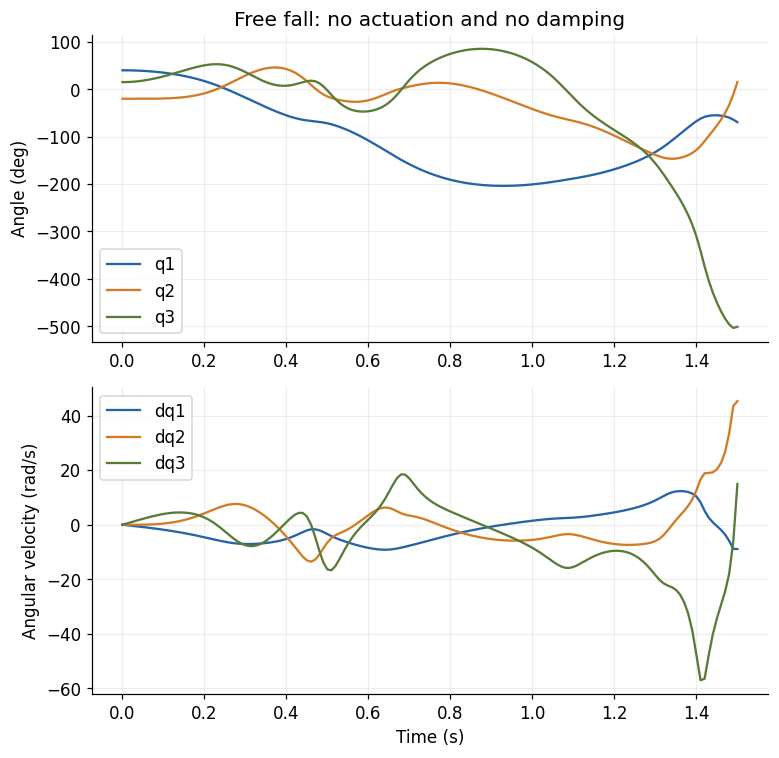

In [25]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

def com_data(q):
    """pc[i], Jv[i], Jw[i]：第 i 根连杆质心位置及速度雅可比。"""
    P = joint_points(q)
    alpha = np.cumsum(q)
    pc = P[:3] + np.column_stack((lc*np.cos(alpha), lc*np.sin(alpha), np.zeros(3)))
    Jv, Jw = np.zeros((3, 3, 3)), np.zeros((3, 3, 3))
    z = np.array([0., 0., 1.])
    for i in range(3):
        for j in range(i+1):
            Jv[i, :, j] = np.cross(z, pc[i]-P[j])
            Jw[i, :, j] = z
    return pc, Jv, Jw

def mass_matrix(q):
    _, Jv, Jw = com_data(q)
    H = np.zeros((3, 3))  # 用 H 区分质量矩阵和零位变换 M
    for i in range(3):
        H += m[i]*(Jv[i].T @ Jv[i]) + Izz[i]*np.outer(Jw[i, 2], Jw[i, 2])
    return H

def mass_derivatives_fd(q, h=1e-5):
    dH = np.zeros((3, 3, 3))  # dH[k,i,j] = partial H[i,j]/partial q[k]
    for k in range(3):
        e = np.eye(3)[k]*h
        dH[k] = (mass_matrix(q+e)-mass_matrix(q-e))/(2*h)
    return dH

def mass_derivatives(q):
    # 解析导数用于仿真加速；与有限差分导数进行交叉验证。
    alpha = np.cumsum(q)
    _, Jv, _ = com_data(q)
    dH = np.zeros((3, 3, 3))
    for i in range(3):
        for k in range(i+1):
            dJ = np.zeros((3, 3))
            for j in range(i+1):
                for a in range(max(j, k), i+1):
                    length = lc[i] if a == i else l[a]
                    dJ[:2, j] -= length*np.array([np.cos(alpha[a]), np.sin(alpha[a])])
            dH[k] += m[i]*(dJ.T @ Jv[i] + Jv[i].T @ dJ)
    return dH

def coriolis_matrix(q, dq):
    dH = mass_derivatives(q)
    C = np.zeros((3, 3))
    for i in range(3):
        for j in range(3):
            for k in range(3):
                Gamma_ijk = 0.5*(dH[k, i, j]+dH[j, i, k]-dH[i, j, k])
                C[i, j] += Gamma_ijk*dq[k]
    return C

def coriolis(q, dq):
    return coriolis_matrix(q, dq) @ dq

def gravity(q):
    _, Jv, _ = com_data(q)
    g = np.zeros(3)
    for i in range(3): g += m[i]*g0*Jv[i, 1, :]
    return g

def inverse_dynamics(q, dq, ddq):
    return mass_matrix(q) @ ddq + coriolis(q, dq) + gravity(q)

def forward_dynamics(q, dq, tau):
    return np.linalg.solve(mass_matrix(q), tau-coriolis(q, dq)-gravity(q))

def kinetic(q, dq):
    _, Jv, Jw = com_data(q)
    K = 0.0
    for i in range(3):
        vc, wc = Jv[i] @ dq, Jw[i] @ dq
        K += 0.5*m[i]*(vc @ vc) + 0.5*Izz[i]*wc[2]**2
    return K

def potential(q):
    pc, _, _ = com_data(q)
    return g0 * (m @ pc[:, 1])

# ===== 本节公式的实现 =====
def rk4_step(f, t, x, dt):
    k1 = f(t, x)
    k2 = f(t+dt/2, x+dt*k1/2)
    k3 = f(t+dt/2, x+dt*k2/2)
    k4 = f(t+dt, x+dt*k3)
    return x + dt*(k1+2*k2+2*k3+k4)/6

def simulate(controller, q0, dq0, duration=2.0, dt=0.01):
    n = int(round(duration/dt))
    ts = np.arange(n+1)*dt
    X, Tau = np.zeros((n+1, 6)), np.zeros((n+1, 3))
    X[0] = np.r_[q0, dq0]
    def f(t, x):
        q, dq = x[:3], x[3:]
        tau = controller(t, q, dq)
        return np.r_[dq, forward_dynamics(q, dq, tau)]
    for k in range(n):
        Tau[k] = controller(ts[k], X[k, :3], X[k, 3:])
        X[k+1] = rk4_step(f, ts[k], X[k], dt)
        if not np.all(np.isfinite(X[k+1])) or np.linalg.norm(X[k+1]) > 1e5:
            raise RuntimeError('积分发散：减小 dt 或控制增益。')
    Tau[-1] = controller(ts[-1], X[-1, :3], X[-1, 3:])
    return ts, X, Tau

# ===== 本节实验：优先阅读并修改这里 =====
zero_torque = lambda t,q,dq: np.zeros(3)
q0, dq0 = np.deg2rad([40.,-20.,15.]), np.zeros(3)
ts, X, Tau = simulate(zero_torque,q0,dq0,duration=1.5,dt=0.01)
fig, axes = plt.subplots(2,1,figsize=(7.2,7.0))
for j in range(3):
    axes[0].plot(ts,np.rad2deg(X[:,j]),color=colors[j],label='q%d' % (j+1))
    axes[1].plot(ts,X[:,j+3],color=colors[j],label='dq%d' % (j+1))
axes[0].set(ylabel='Angle (deg)',title='Free fall: no actuation and no damping')
axes[1].set(xlabel='Time (s)',ylabel='Angular velocity (rad/s)')
axes[0].legend(); axes[1].legend(); fig.tight_layout(); plt.show()
print('final angles (deg):', np.rad2deg(X[-1,:3]))


## 25｜能量守恒与步长收敛：检验积分器
理想无驱动、无摩擦系统满足 $E=K+U=\text{常量}$。数值积分器只能近似保持：
$$\epsilon_E(t)=\frac{E(t)-E(0)}{\max(|E(0)|,1\,\mathrm J)}.$$

下面比较 Euler 与 RK4，并把 RK4 步长减半。Euler 一阶、RK4 四阶，但 RK4 **不是能量严格守恒或辛积分器**；短时间、光滑问题通常随步长减小明显改善，不保证长时间能量不漂移。

以更小步长的 RK4 末状态作参考只是数值收敛检查，并不是精确解。默认测试只跑短时间，避免在 iPad 上等待过久。

**练习**：延长到 5 s；观察同一控制增益下步长与稳定性、耗时的关系。


Euler 0.01 max normalized energy drift: 0.267500835266406
RK4 0.01 max normalized energy drift: 3.839177576895509e-05
RK4 0.005 max normalized energy drift: 2.5648520553267125e-06
state error vs RK4(dt=0.0025), coarse/fine: 0.0012917815005824946 6.328297465481922e-05


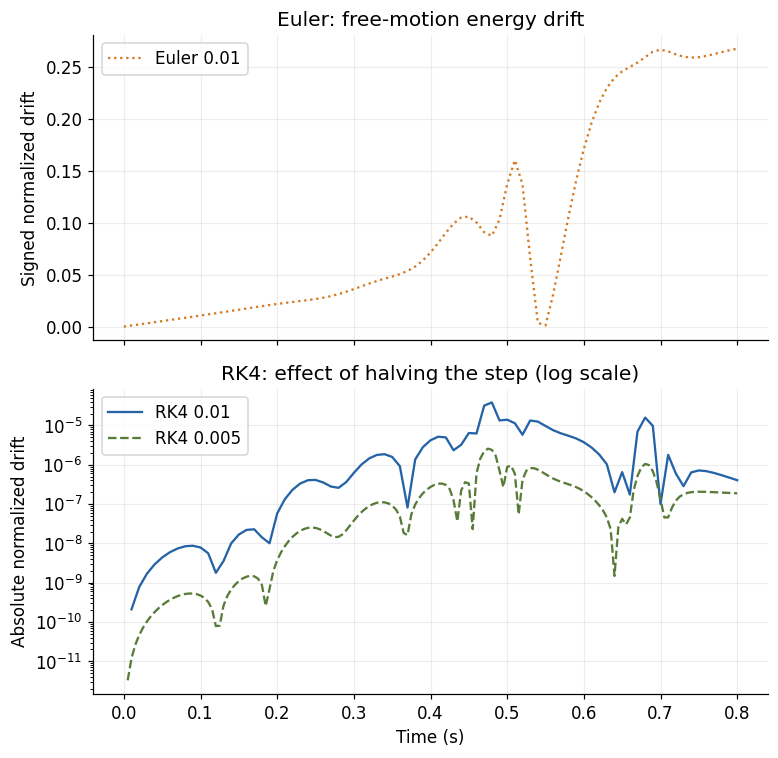

In [26]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

def com_data(q):
    """pc[i], Jv[i], Jw[i]：第 i 根连杆质心位置及速度雅可比。"""
    P = joint_points(q)
    alpha = np.cumsum(q)
    pc = P[:3] + np.column_stack((lc*np.cos(alpha), lc*np.sin(alpha), np.zeros(3)))
    Jv, Jw = np.zeros((3, 3, 3)), np.zeros((3, 3, 3))
    z = np.array([0., 0., 1.])
    for i in range(3):
        for j in range(i+1):
            Jv[i, :, j] = np.cross(z, pc[i]-P[j])
            Jw[i, :, j] = z
    return pc, Jv, Jw

def mass_matrix(q):
    _, Jv, Jw = com_data(q)
    H = np.zeros((3, 3))  # 用 H 区分质量矩阵和零位变换 M
    for i in range(3):
        H += m[i]*(Jv[i].T @ Jv[i]) + Izz[i]*np.outer(Jw[i, 2], Jw[i, 2])
    return H

def mass_derivatives_fd(q, h=1e-5):
    dH = np.zeros((3, 3, 3))  # dH[k,i,j] = partial H[i,j]/partial q[k]
    for k in range(3):
        e = np.eye(3)[k]*h
        dH[k] = (mass_matrix(q+e)-mass_matrix(q-e))/(2*h)
    return dH

def mass_derivatives(q):
    # 解析导数用于仿真加速；与有限差分导数进行交叉验证。
    alpha = np.cumsum(q)
    _, Jv, _ = com_data(q)
    dH = np.zeros((3, 3, 3))
    for i in range(3):
        for k in range(i+1):
            dJ = np.zeros((3, 3))
            for j in range(i+1):
                for a in range(max(j, k), i+1):
                    length = lc[i] if a == i else l[a]
                    dJ[:2, j] -= length*np.array([np.cos(alpha[a]), np.sin(alpha[a])])
            dH[k] += m[i]*(dJ.T @ Jv[i] + Jv[i].T @ dJ)
    return dH

def coriolis_matrix(q, dq):
    dH = mass_derivatives(q)
    C = np.zeros((3, 3))
    for i in range(3):
        for j in range(3):
            for k in range(3):
                Gamma_ijk = 0.5*(dH[k, i, j]+dH[j, i, k]-dH[i, j, k])
                C[i, j] += Gamma_ijk*dq[k]
    return C

def coriolis(q, dq):
    return coriolis_matrix(q, dq) @ dq

def gravity(q):
    _, Jv, _ = com_data(q)
    g = np.zeros(3)
    for i in range(3): g += m[i]*g0*Jv[i, 1, :]
    return g

def inverse_dynamics(q, dq, ddq):
    return mass_matrix(q) @ ddq + coriolis(q, dq) + gravity(q)

def forward_dynamics(q, dq, tau):
    return np.linalg.solve(mass_matrix(q), tau-coriolis(q, dq)-gravity(q))

def rk4_step(f, t, x, dt):
    k1 = f(t, x)
    k2 = f(t+dt/2, x+dt*k1/2)
    k3 = f(t+dt/2, x+dt*k2/2)
    k4 = f(t+dt, x+dt*k3)
    return x + dt*(k1+2*k2+2*k3+k4)/6

def simulate(controller, q0, dq0, duration=2.0, dt=0.01):
    n = int(round(duration/dt))
    ts = np.arange(n+1)*dt
    X, Tau = np.zeros((n+1, 6)), np.zeros((n+1, 3))
    X[0] = np.r_[q0, dq0]
    def f(t, x):
        q, dq = x[:3], x[3:]
        tau = controller(t, q, dq)
        return np.r_[dq, forward_dynamics(q, dq, tau)]
    for k in range(n):
        Tau[k] = controller(ts[k], X[k, :3], X[k, 3:])
        X[k+1] = rk4_step(f, ts[k], X[k], dt)
        if not np.all(np.isfinite(X[k+1])) or np.linalg.norm(X[k+1]) > 1e5:
            raise RuntimeError('积分发散：减小 dt 或控制增益。')
    Tau[-1] = controller(ts[-1], X[-1, :3], X[-1, 3:])
    return ts, X, Tau

def kinetic(q, dq):
    _, Jv, Jw = com_data(q)
    K = 0.0
    for i in range(3):
        vc, wc = Jv[i] @ dq, Jw[i] @ dq
        K += 0.5*m[i]*(vc @ vc) + 0.5*Izz[i]*wc[2]**2
    return K

def potential(q):
    pc, _, _ = com_data(q)
    return g0 * (m @ pc[:, 1])

# ===== 本节实验：优先阅读并修改这里 =====
q0, dq0, duration = np.deg2rad([40.,-20.,15.]), np.zeros(3), 0.8
def free_f(t,x):
    return np.r_[x[3:],forward_dynamics(x[:3],x[3:],np.zeros(3))]
def run_free(dt, method):
    n = int(round(duration/dt))
    ts, X = np.arange(n+1)*dt, np.zeros((n+1,6))
    X[0] = np.r_[q0,dq0]
    for k in range(n):
        X[k+1] = X[k]+dt*free_f(ts[k],X[k]) if method=='Euler' else rk4_step(free_f,ts[k],X[k],dt)
    E = np.array([kinetic(x[:3],x[3:])+potential(x[:3]) for x in X])
    return ts,X,E
fig, axes = plt.subplots(2,1,figsize=(7.2,7.0),sharex=True)
drifts, endpoints = {}, {}
for label,dt,method,col,ls in [('Euler 0.01',0.01,'Euler',colors[1],':'),
                              ('RK4 0.01',0.01,'RK4',colors[0],'-'),
                              ('RK4 0.005',0.005,'RK4',colors[2],'--')]:
    ts,X,E = run_free(dt,method)
    relative = (E-E[0])/max(abs(E[0]),1.)
    drifts[label], endpoints[label] = np.max(np.abs(relative)), X[-1]
    if method=='Euler':
        axes[0].plot(ts,relative,label=label,color=col,linestyle=ls)
    else:
        # log 图不绘制 t=0 的精确零，避免将零值伪装成观测到的正误差。
        axes[1].semilogy(ts[1:],np.maximum(np.abs(relative[1:]),1e-16),
                         label=label,color=col,linestyle=ls)
    print(label,'max normalized energy drift:',drifts[label])
_, Xref, _ = run_free(0.0025,'RK4')
err_coarse = np.linalg.norm(endpoints['RK4 0.01']-Xref[-1])
err_fine = np.linalg.norm(endpoints['RK4 0.005']-Xref[-1])
assert drifts['RK4 0.005'] < drifts['RK4 0.01'] < drifts['Euler 0.01']
assert err_fine < err_coarse
print('state error vs RK4(dt=0.0025), coarse/fine:',err_coarse,err_fine)
axes[0].set(ylabel='Signed normalized drift',title='Euler: free-motion energy drift')
axes[1].set(xlabel='Time (s)',ylabel='Absolute normalized drift',title='RK4: effect of halving the step (log scale)')
axes[0].legend(); axes[1].legend(); fig.tight_layout(); plt.show()


## 26｜定点 PD 与重力补偿：为什么会有静差
给定常数目标 $q_d$：
$$\tau_{PD}=K_p(q_d-q)-K_d\dot q,$$
$$\tau_{PD+g}=K_p(q_d-q)-K_d\dot q+g(q).$$

PD 的位置误差需要产生支撑力矩，平衡时大致有 $K_p(q_d-q)=g(q)$，因此一般存在静差。加上准确重力补偿后，目标处 $e=0,\dot q=0$ 就能提供所需力矩。

$K_p$ 单位为 N·m/rad，$K_d$ 为 N·m·s/rad，下面使用逐关节对角增益。先在**目标状态**检查加速度，再做有限时长仿真。短时仿真末误差不等于严格稳态误差。

**练习**：降低 `Kp`，比较未补偿 PD 的误差；把补偿乘以 0.8，观察模型偏差影响。


acceleration at exact target, PD: [-20.157369   1.5931    46.340324]
acceleration at exact target, PD+g: [0. 0. 0.]
PD finite-time final error (deg): [18.958191 13.212115 14.583697]
PD+g finite-time final error (deg): [-0.029039 -0.027946  0.077179]


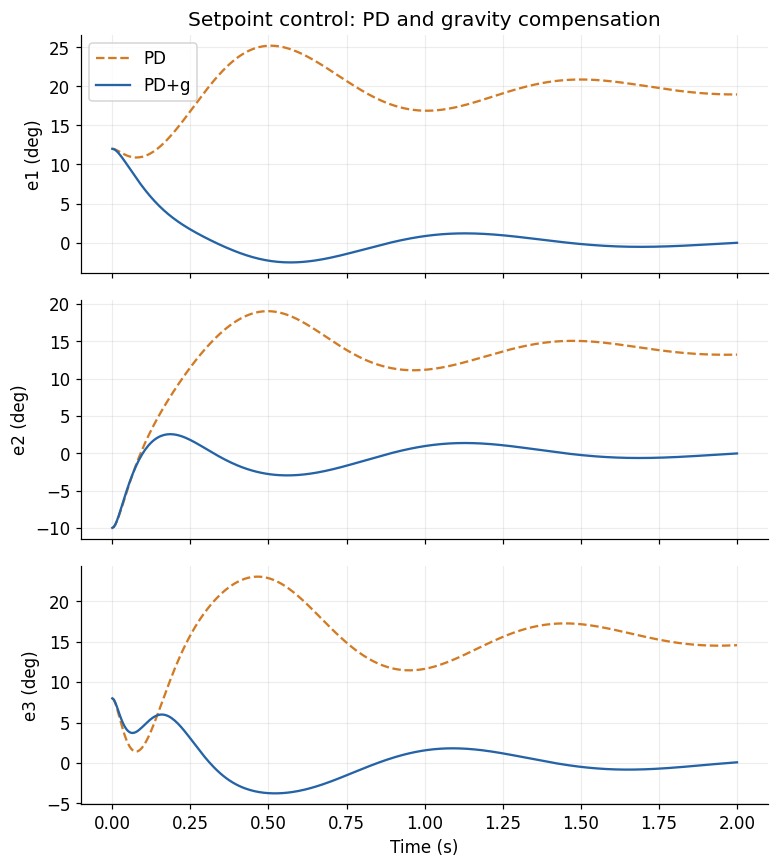

In [27]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

def com_data(q):
    """pc[i], Jv[i], Jw[i]：第 i 根连杆质心位置及速度雅可比。"""
    P = joint_points(q)
    alpha = np.cumsum(q)
    pc = P[:3] + np.column_stack((lc*np.cos(alpha), lc*np.sin(alpha), np.zeros(3)))
    Jv, Jw = np.zeros((3, 3, 3)), np.zeros((3, 3, 3))
    z = np.array([0., 0., 1.])
    for i in range(3):
        for j in range(i+1):
            Jv[i, :, j] = np.cross(z, pc[i]-P[j])
            Jw[i, :, j] = z
    return pc, Jv, Jw

def mass_matrix(q):
    _, Jv, Jw = com_data(q)
    H = np.zeros((3, 3))  # 用 H 区分质量矩阵和零位变换 M
    for i in range(3):
        H += m[i]*(Jv[i].T @ Jv[i]) + Izz[i]*np.outer(Jw[i, 2], Jw[i, 2])
    return H

def mass_derivatives_fd(q, h=1e-5):
    dH = np.zeros((3, 3, 3))  # dH[k,i,j] = partial H[i,j]/partial q[k]
    for k in range(3):
        e = np.eye(3)[k]*h
        dH[k] = (mass_matrix(q+e)-mass_matrix(q-e))/(2*h)
    return dH

def mass_derivatives(q):
    # 解析导数用于仿真加速；与有限差分导数进行交叉验证。
    alpha = np.cumsum(q)
    _, Jv, _ = com_data(q)
    dH = np.zeros((3, 3, 3))
    for i in range(3):
        for k in range(i+1):
            dJ = np.zeros((3, 3))
            for j in range(i+1):
                for a in range(max(j, k), i+1):
                    length = lc[i] if a == i else l[a]
                    dJ[:2, j] -= length*np.array([np.cos(alpha[a]), np.sin(alpha[a])])
            dH[k] += m[i]*(dJ.T @ Jv[i] + Jv[i].T @ dJ)
    return dH

def coriolis_matrix(q, dq):
    dH = mass_derivatives(q)
    C = np.zeros((3, 3))
    for i in range(3):
        for j in range(3):
            for k in range(3):
                Gamma_ijk = 0.5*(dH[k, i, j]+dH[j, i, k]-dH[i, j, k])
                C[i, j] += Gamma_ijk*dq[k]
    return C

def coriolis(q, dq):
    return coriolis_matrix(q, dq) @ dq

def gravity(q):
    _, Jv, _ = com_data(q)
    g = np.zeros(3)
    for i in range(3): g += m[i]*g0*Jv[i, 1, :]
    return g

def inverse_dynamics(q, dq, ddq):
    return mass_matrix(q) @ ddq + coriolis(q, dq) + gravity(q)

def forward_dynamics(q, dq, tau):
    return np.linalg.solve(mass_matrix(q), tau-coriolis(q, dq)-gravity(q))

def rk4_step(f, t, x, dt):
    k1 = f(t, x)
    k2 = f(t+dt/2, x+dt*k1/2)
    k3 = f(t+dt/2, x+dt*k2/2)
    k4 = f(t+dt, x+dt*k3)
    return x + dt*(k1+2*k2+2*k3+k4)/6

def simulate(controller, q0, dq0, duration=2.0, dt=0.01):
    n = int(round(duration/dt))
    ts = np.arange(n+1)*dt
    X, Tau = np.zeros((n+1, 6)), np.zeros((n+1, 3))
    X[0] = np.r_[q0, dq0]
    def f(t, x):
        q, dq = x[:3], x[3:]
        tau = controller(t, q, dq)
        return np.r_[dq, forward_dynamics(q, dq, tau)]
    for k in range(n):
        Tau[k] = controller(ts[k], X[k, :3], X[k, 3:])
        X[k+1] = rk4_step(f, ts[k], X[k], dt)
        if not np.all(np.isfinite(X[k+1])) or np.linalg.norm(X[k+1]) > 1e5:
            raise RuntimeError('积分发散：减小 dt 或控制增益。')
    Tau[-1] = controller(ts[-1], X[-1, :3], X[-1, 3:])
    return ts, X, Tau

# ===== 本节实验：优先阅读并修改这里 =====
qd = np.deg2rad([30.,-40.,35.])
Kp, Kd = np.array([35.,12.,2.]), np.array([3.,1.,0.1])
def pd(t,q,dq): return Kp*(qd-q)-Kd*dq
def pdg(t,q,dq): return pd(t,q,dq)+gravity(q)
assert np.linalg.norm(forward_dynamics(qd,np.zeros(3),pdg(0,qd,np.zeros(3)))) < 1e-10
print('acceleration at exact target, PD:',forward_dynamics(qd,np.zeros(3),pd(0,qd,np.zeros(3))))
print('acceleration at exact target, PD+g:',forward_dynamics(qd,np.zeros(3),pdg(0,qd,np.zeros(3))))
q0, dq0 = qd+np.deg2rad([-12.,10.,-8.]), np.zeros(3)
fig, axes = plt.subplots(3,1,figsize=(7.2,8.0),sharex=True)
for label,controller,col,ls in [('PD',pd,colors[1],'--'),('PD+g',pdg,colors[0],'-')]:
    ts,X,Tau = simulate(controller,q0,dq0,duration=2.0,dt=0.005)
    for j,ax in enumerate(axes):
        ax.plot(ts,np.rad2deg(qd[j]-X[:,j]),label=label,color=col,linestyle=ls)
        ax.set_ylabel('e%d (deg)' % (j+1))
    print(label,'finite-time final error (deg):',np.rad2deg(qd-X[-1,:3]))
axes[0].set_title('Setpoint control: PD and gravity compensation')
axes[0].legend(); axes[-1].set_xlabel('Time (s)')
fig.tight_layout(); plt.show()


## 27｜轨迹与计算力矩控制：把动力学耦合补偿掉
给定光滑关节轨迹及其**解析速度、加速度**：
$$q_d=q_{off}+A\sin(\nu t),\quad\dot q_d=A\nu\cos(\nu t),\quad
\ddot q_d=-A\nu^2\sin(\nu t).$$
这里 $\nu$ 单位 rad/s，不是 Hz；若用 Hz，应乘 $2\pi$。

令 $e=q_d-q$，计算力矩控制采用
$$a=\ddot q_d+k_d(\dot q_d-\dot q)+k_p(q_d-q),$$
$$\tau=H(q)a+c(q,\dot q)+g(q).$$

模型完全准确、无饱和时 $\ddot q=a$，所以
$$\ddot e+k_d\dot e+k_pe=0.$$
这时 $k_p$ 单位 s⁻²，$k_d$ 单位 s⁻¹，与直接输出力矩的 PD 增益单位不同。选 $k_p=\omega_n^2,k_d=2\zeta\omega_n$；默认 $\omega_n=6\,\mathrm{s^{-1}},\zeta=1$。

先检查一个任意状态下，实际正动力学给出的加速度是否等于所构造的 $a$。**练习**：删掉 $c$，提高目标速度，比较跟踪变化。


In [28]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

def com_data(q):
    """pc[i], Jv[i], Jw[i]：第 i 根连杆质心位置及速度雅可比。"""
    P = joint_points(q)
    alpha = np.cumsum(q)
    pc = P[:3] + np.column_stack((lc*np.cos(alpha), lc*np.sin(alpha), np.zeros(3)))
    Jv, Jw = np.zeros((3, 3, 3)), np.zeros((3, 3, 3))
    z = np.array([0., 0., 1.])
    for i in range(3):
        for j in range(i+1):
            Jv[i, :, j] = np.cross(z, pc[i]-P[j])
            Jw[i, :, j] = z
    return pc, Jv, Jw

def mass_matrix(q):
    _, Jv, Jw = com_data(q)
    H = np.zeros((3, 3))  # 用 H 区分质量矩阵和零位变换 M
    for i in range(3):
        H += m[i]*(Jv[i].T @ Jv[i]) + Izz[i]*np.outer(Jw[i, 2], Jw[i, 2])
    return H

def mass_derivatives_fd(q, h=1e-5):
    dH = np.zeros((3, 3, 3))  # dH[k,i,j] = partial H[i,j]/partial q[k]
    for k in range(3):
        e = np.eye(3)[k]*h
        dH[k] = (mass_matrix(q+e)-mass_matrix(q-e))/(2*h)
    return dH

def mass_derivatives(q):
    # 解析导数用于仿真加速；与有限差分导数进行交叉验证。
    alpha = np.cumsum(q)
    _, Jv, _ = com_data(q)
    dH = np.zeros((3, 3, 3))
    for i in range(3):
        for k in range(i+1):
            dJ = np.zeros((3, 3))
            for j in range(i+1):
                for a in range(max(j, k), i+1):
                    length = lc[i] if a == i else l[a]
                    dJ[:2, j] -= length*np.array([np.cos(alpha[a]), np.sin(alpha[a])])
            dH[k] += m[i]*(dJ.T @ Jv[i] + Jv[i].T @ dJ)
    return dH

def coriolis_matrix(q, dq):
    dH = mass_derivatives(q)
    C = np.zeros((3, 3))
    for i in range(3):
        for j in range(3):
            for k in range(3):
                Gamma_ijk = 0.5*(dH[k, i, j]+dH[j, i, k]-dH[i, j, k])
                C[i, j] += Gamma_ijk*dq[k]
    return C

def coriolis(q, dq):
    return coriolis_matrix(q, dq) @ dq

def gravity(q):
    _, Jv, _ = com_data(q)
    g = np.zeros(3)
    for i in range(3): g += m[i]*g0*Jv[i, 1, :]
    return g

def inverse_dynamics(q, dq, ddq):
    return mass_matrix(q) @ ddq + coriolis(q, dq) + gravity(q)

def forward_dynamics(q, dq, tau):
    return np.linalg.solve(mass_matrix(q), tau-coriolis(q, dq)-gravity(q))

def reference(t):
    offset = np.deg2rad([25., -35., 25.])
    amp = np.deg2rad([12., 10., 8.])
    freq = np.array([1.0, 1.3, 0.8])  # rad/s；不是 Hz
    qd = offset + amp*np.sin(freq*t)
    dqd = amp*freq*np.cos(freq*t)
    ddqd = -amp*freq**2*np.sin(freq*t)
    return qd, dqd, ddqd

# ===== 本节公式的实现 =====
def make_controller(mode, torque_limit=None):
    # PD 的 Kp、Kd 单位分别为 Nm/rad、Nm s/rad。
    Kp, Kd = np.array([35., 12., 2.]), np.array([3., 1., 0.1])
    # 计算力矩的 kp、kd 单位分别为 1/s^2、1/s。
    kp, kd = np.array([36., 36., 36.]), np.array([12., 12., 12.])
    def controller(t, q, dq):
        qd, dqd, ddqd = reference(t)
        e, de = qd-q, dqd-dq
        if mode == 'PD':
            tau = Kp*e + Kd*de
        elif mode == 'PD+g':
            tau = Kp*e + Kd*de + gravity(q)
        elif mode == 'CT':
            a = ddqd + kp*e + kd*de
            tau = mass_matrix(q) @ a + coriolis(q, dq) + gravity(q)
        else:
            raise ValueError('mode 必须为 PD、PD+g 或 CT')
        if torque_limit is not None: tau = np.clip(tau, -torque_limit, torque_limit)
        return tau
    return controller

# ===== 本节实验：优先阅读并修改这里 =====
t, q, dq = 0.7, q_demo.copy(), np.array([0.4,-0.2,0.3])
qd,dqd,ddqd = reference(t)
kp, kd = np.ones(3)*36., np.ones(3)*12.
a = ddqd+kp*(qd-q)+kd*(dqd-dq)
tau = make_controller('CT')(t,q,dq)
assert np.allclose(forward_dynamics(q,dq,tau), a, atol=1e-10)
# 参考轨迹的速度和加速度也用差分检查。
h = 1e-4
assert np.allclose((reference(t+h)[0]-reference(t-h)[0])/(2*h),dqd,atol=1e-8)
assert np.allclose((reference(t+h)[1]-reference(t-h)[1])/(2*h),ddqd,atol=1e-8)
print('reference q,dq,ddq:',qd,dqd,ddqd)
print('command / actual acceleration:',a,forward_dynamics(q,dq,tau))
print('CT torque (Nm):',tau)


reference q,dq,ddq: [ 0.571257 -0.473071  0.5105  ] [0.160188 0.139254 0.094639] [-0.134925 -0.232873 -0.047467]
command / actual acceleration: [ -1.296972  15.081965 -21.832911] [ -1.296972  15.081965 -21.832911]
CT torque (Nm): [13.172508  4.520047  0.447435]


## 28｜同一条轨迹，对比 PD、PD+g、计算力矩
使用相同初始状态、参考轨迹与积分方法，对比三种控制器。三者使用各自说明的增益，**增益没有做最优化，因此这不是算法优劣的公平性能排名**；本实验展示重力项、惯性前馈和耦合补偿的作用。

记录每个关节误差、驱动力矩与总误差范数。计算全时段角度 RMSE 与后半时段 RMSE，避免把初始误差与持续跟踪误差混为一谈。所有方法均使用同一理想模型，无噪声、无延迟、无力矩限幅。

**检查**：计算力矩控制的误差应与理论方程一致，最后误差显著小于初始误差。图中力矩仍以 N·m 展示，而不是用缩放后的视觉曲线代替实际力矩。


PD all-time RMSE (deg): [19.968836 15.65122  16.13707 ]
    late-half RMSE (deg): [19.978707 16.166677 16.366818] peak |tau| (Nm): [15.840344  4.357968  0.775772]
PD+g all-time RMSE (deg): [3.375048 2.383822 3.286345]
    late-half RMSE (deg): [0.675164 0.775348 0.897881] peak |tau| (Nm): [22.615173  5.504242  0.999441]
CT all-time RMSE (deg): [4.582507 3.235465 3.024072]
    late-half RMSE (deg): [0.021842 0.013114 0.014253] peak |tau| (Nm): [20.881289  6.573131  1.113732]


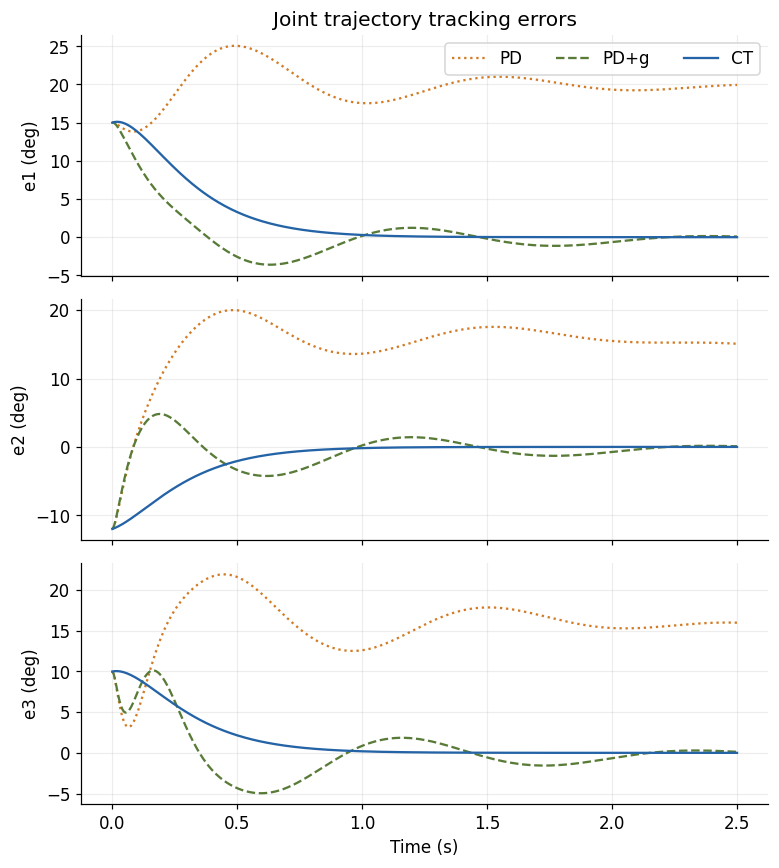

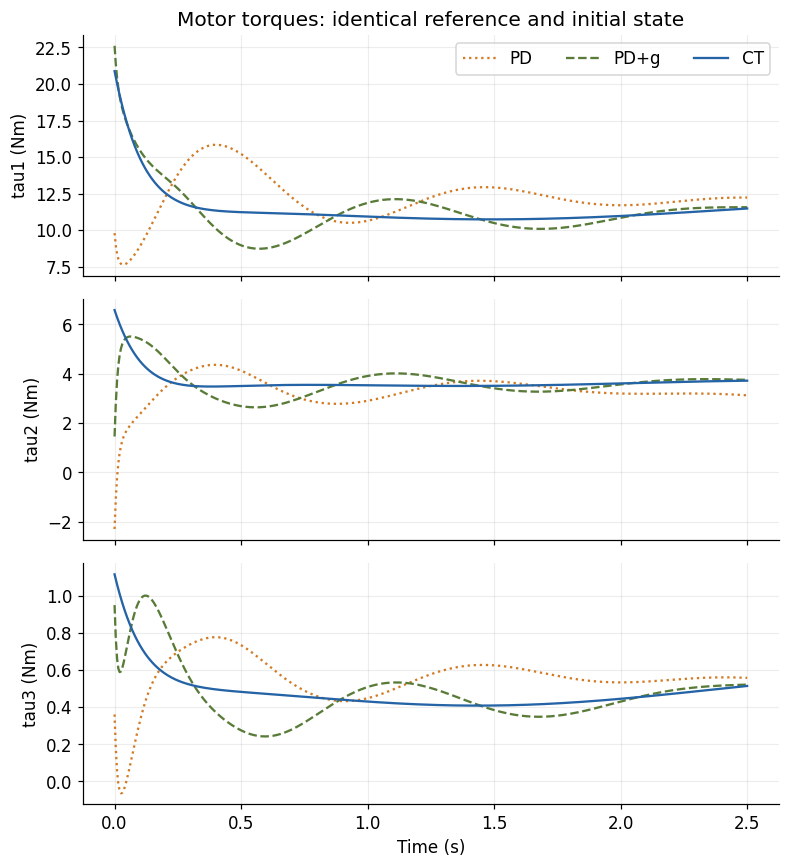

In [29]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

def com_data(q):
    """pc[i], Jv[i], Jw[i]：第 i 根连杆质心位置及速度雅可比。"""
    P = joint_points(q)
    alpha = np.cumsum(q)
    pc = P[:3] + np.column_stack((lc*np.cos(alpha), lc*np.sin(alpha), np.zeros(3)))
    Jv, Jw = np.zeros((3, 3, 3)), np.zeros((3, 3, 3))
    z = np.array([0., 0., 1.])
    for i in range(3):
        for j in range(i+1):
            Jv[i, :, j] = np.cross(z, pc[i]-P[j])
            Jw[i, :, j] = z
    return pc, Jv, Jw

def mass_matrix(q):
    _, Jv, Jw = com_data(q)
    H = np.zeros((3, 3))  # 用 H 区分质量矩阵和零位变换 M
    for i in range(3):
        H += m[i]*(Jv[i].T @ Jv[i]) + Izz[i]*np.outer(Jw[i, 2], Jw[i, 2])
    return H

def mass_derivatives_fd(q, h=1e-5):
    dH = np.zeros((3, 3, 3))  # dH[k,i,j] = partial H[i,j]/partial q[k]
    for k in range(3):
        e = np.eye(3)[k]*h
        dH[k] = (mass_matrix(q+e)-mass_matrix(q-e))/(2*h)
    return dH

def mass_derivatives(q):
    # 解析导数用于仿真加速；与有限差分导数进行交叉验证。
    alpha = np.cumsum(q)
    _, Jv, _ = com_data(q)
    dH = np.zeros((3, 3, 3))
    for i in range(3):
        for k in range(i+1):
            dJ = np.zeros((3, 3))
            for j in range(i+1):
                for a in range(max(j, k), i+1):
                    length = lc[i] if a == i else l[a]
                    dJ[:2, j] -= length*np.array([np.cos(alpha[a]), np.sin(alpha[a])])
            dH[k] += m[i]*(dJ.T @ Jv[i] + Jv[i].T @ dJ)
    return dH

def coriolis_matrix(q, dq):
    dH = mass_derivatives(q)
    C = np.zeros((3, 3))
    for i in range(3):
        for j in range(3):
            for k in range(3):
                Gamma_ijk = 0.5*(dH[k, i, j]+dH[j, i, k]-dH[i, j, k])
                C[i, j] += Gamma_ijk*dq[k]
    return C

def coriolis(q, dq):
    return coriolis_matrix(q, dq) @ dq

def gravity(q):
    _, Jv, _ = com_data(q)
    g = np.zeros(3)
    for i in range(3): g += m[i]*g0*Jv[i, 1, :]
    return g

def inverse_dynamics(q, dq, ddq):
    return mass_matrix(q) @ ddq + coriolis(q, dq) + gravity(q)

def forward_dynamics(q, dq, tau):
    return np.linalg.solve(mass_matrix(q), tau-coriolis(q, dq)-gravity(q))

def rk4_step(f, t, x, dt):
    k1 = f(t, x)
    k2 = f(t+dt/2, x+dt*k1/2)
    k3 = f(t+dt/2, x+dt*k2/2)
    k4 = f(t+dt, x+dt*k3)
    return x + dt*(k1+2*k2+2*k3+k4)/6

def simulate(controller, q0, dq0, duration=2.0, dt=0.01):
    n = int(round(duration/dt))
    ts = np.arange(n+1)*dt
    X, Tau = np.zeros((n+1, 6)), np.zeros((n+1, 3))
    X[0] = np.r_[q0, dq0]
    def f(t, x):
        q, dq = x[:3], x[3:]
        tau = controller(t, q, dq)
        return np.r_[dq, forward_dynamics(q, dq, tau)]
    for k in range(n):
        Tau[k] = controller(ts[k], X[k, :3], X[k, 3:])
        X[k+1] = rk4_step(f, ts[k], X[k], dt)
        if not np.all(np.isfinite(X[k+1])) or np.linalg.norm(X[k+1]) > 1e5:
            raise RuntimeError('积分发散：减小 dt 或控制增益。')
    Tau[-1] = controller(ts[-1], X[-1, :3], X[-1, 3:])
    return ts, X, Tau

def reference(t):
    offset = np.deg2rad([25., -35., 25.])
    amp = np.deg2rad([12., 10., 8.])
    freq = np.array([1.0, 1.3, 0.8])  # rad/s；不是 Hz
    qd = offset + amp*np.sin(freq*t)
    dqd = amp*freq*np.cos(freq*t)
    ddqd = -amp*freq**2*np.sin(freq*t)
    return qd, dqd, ddqd

def make_controller(mode, torque_limit=None):
    # PD 的 Kp、Kd 单位分别为 Nm/rad、Nm s/rad。
    Kp, Kd = np.array([35., 12., 2.]), np.array([3., 1., 0.1])
    # 计算力矩的 kp、kd 单位分别为 1/s^2、1/s。
    kp, kd = np.array([36., 36., 36.]), np.array([12., 12., 12.])
    def controller(t, q, dq):
        qd, dqd, ddqd = reference(t)
        e, de = qd-q, dqd-dq
        if mode == 'PD':
            tau = Kp*e + Kd*de
        elif mode == 'PD+g':
            tau = Kp*e + Kd*de + gravity(q)
        elif mode == 'CT':
            a = ddqd + kp*e + kd*de
            tau = mass_matrix(q) @ a + coriolis(q, dq) + gravity(q)
        else:
            raise ValueError('mode 必须为 PD、PD+g 或 CT')
        if torque_limit is not None: tau = np.clip(tau, -torque_limit, torque_limit)
        return tau
    return controller

# ===== 本节实验：优先阅读并修改这里 =====
qd0,_,_ = reference(0.)
q0,dq0 = qd0+np.deg2rad([-15.,12.,-10.]),np.zeros(3)
results = {}
for mode in ['PD','PD+g','CT']:
    ts,X,Tau = simulate(make_controller(mode),q0,dq0,duration=2.5,dt=0.005)
    Qd = np.array([reference(t)[0] for t in ts])
    e = Qd-X[:,:3]
    rmse_all = np.rad2deg(np.sqrt(np.mean(e**2,axis=0)))
    rmse_late = np.rad2deg(np.sqrt(np.mean(e[len(e)//2:]**2,axis=0)))
    results[mode] = (ts,X,Tau,e)
    print(mode,'all-time RMSE (deg):',rmse_all)
    print('    late-half RMSE (deg):',rmse_late,'peak |tau| (Nm):',np.max(np.abs(Tau),axis=0))
assert np.linalg.norm(results['CT'][3][-1]) < 0.01*np.linalg.norm(results['CT'][3][0])
fig, axes = plt.subplots(3,1,figsize=(7.2,8.0),sharex=True)
styles = [('PD',colors[1],':'),('PD+g',colors[2],'--'),('CT',colors[0],'-')]
for mode,col,ls in styles:
    ts,X,Tau,e = results[mode]
    for j,ax in enumerate(axes):
        ax.plot(ts,np.rad2deg(e[:,j]),label=mode,color=col,linestyle=ls)
        ax.set_ylabel('e%d (deg)' % (j+1))
axes[0].legend(ncol=3); axes[0].set_title('Joint trajectory tracking errors')
axes[-1].set_xlabel('Time (s)'); fig.tight_layout(); plt.show()
fig, axes = plt.subplots(3,1,figsize=(7.2,8.0),sharex=True)
for mode,col,ls in styles:
    ts,X,Tau,e = results[mode]
    for j,ax in enumerate(axes):
        ax.plot(ts,Tau[:,j],label=mode,color=col,linestyle=ls)
        ax.set_ylabel('tau%d (Nm)' % (j+1))
axes[0].legend(ncol=3); axes[0].set_title('Motor torques: identical reference and initial state')
axes[-1].set_xlabel('Time (s)'); fig.tight_layout(); plt.show()


## 29｜给计算力矩加限幅：理想误差方程何时失效
实际驱动有力矩上限。这里仅加入
$$\tau_{applied}=\operatorname{clip}(\tau_{CT},-\tau_{max},\tau_{max}).$$

一旦发生限幅，$\ddot q=a$ 不再成立，理想二阶误差方程也不再成立。与无限幅计算力矩对比时，保持其他条件相同。本节不是电机、减速器或真实伺服系统模型。

**练习**：把限幅从每关节 3 N·m 调到 `[15, 5, 2]`，思考第一关节支撑整条手臂所需力矩为什么更大。也可在控制器中把 $H,c,g$ 乘以 0.8，模拟简单整体模型失配；保持正动力学模型不变。


Ideal CT final error norm (deg): 0.02768794818026473
Limited CT final error norm (deg): 130.31940283311968


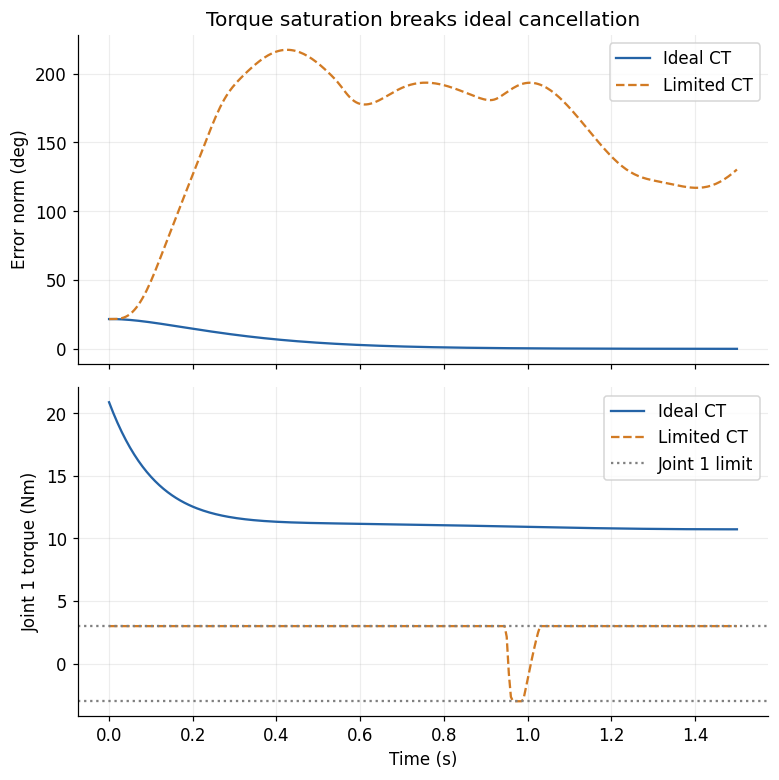

In [30]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

def com_data(q):
    """pc[i], Jv[i], Jw[i]：第 i 根连杆质心位置及速度雅可比。"""
    P = joint_points(q)
    alpha = np.cumsum(q)
    pc = P[:3] + np.column_stack((lc*np.cos(alpha), lc*np.sin(alpha), np.zeros(3)))
    Jv, Jw = np.zeros((3, 3, 3)), np.zeros((3, 3, 3))
    z = np.array([0., 0., 1.])
    for i in range(3):
        for j in range(i+1):
            Jv[i, :, j] = np.cross(z, pc[i]-P[j])
            Jw[i, :, j] = z
    return pc, Jv, Jw

def mass_matrix(q):
    _, Jv, Jw = com_data(q)
    H = np.zeros((3, 3))  # 用 H 区分质量矩阵和零位变换 M
    for i in range(3):
        H += m[i]*(Jv[i].T @ Jv[i]) + Izz[i]*np.outer(Jw[i, 2], Jw[i, 2])
    return H

def mass_derivatives_fd(q, h=1e-5):
    dH = np.zeros((3, 3, 3))  # dH[k,i,j] = partial H[i,j]/partial q[k]
    for k in range(3):
        e = np.eye(3)[k]*h
        dH[k] = (mass_matrix(q+e)-mass_matrix(q-e))/(2*h)
    return dH

def mass_derivatives(q):
    # 解析导数用于仿真加速；与有限差分导数进行交叉验证。
    alpha = np.cumsum(q)
    _, Jv, _ = com_data(q)
    dH = np.zeros((3, 3, 3))
    for i in range(3):
        for k in range(i+1):
            dJ = np.zeros((3, 3))
            for j in range(i+1):
                for a in range(max(j, k), i+1):
                    length = lc[i] if a == i else l[a]
                    dJ[:2, j] -= length*np.array([np.cos(alpha[a]), np.sin(alpha[a])])
            dH[k] += m[i]*(dJ.T @ Jv[i] + Jv[i].T @ dJ)
    return dH

def coriolis_matrix(q, dq):
    dH = mass_derivatives(q)
    C = np.zeros((3, 3))
    for i in range(3):
        for j in range(3):
            for k in range(3):
                Gamma_ijk = 0.5*(dH[k, i, j]+dH[j, i, k]-dH[i, j, k])
                C[i, j] += Gamma_ijk*dq[k]
    return C

def coriolis(q, dq):
    return coriolis_matrix(q, dq) @ dq

def gravity(q):
    _, Jv, _ = com_data(q)
    g = np.zeros(3)
    for i in range(3): g += m[i]*g0*Jv[i, 1, :]
    return g

def inverse_dynamics(q, dq, ddq):
    return mass_matrix(q) @ ddq + coriolis(q, dq) + gravity(q)

def forward_dynamics(q, dq, tau):
    return np.linalg.solve(mass_matrix(q), tau-coriolis(q, dq)-gravity(q))

def rk4_step(f, t, x, dt):
    k1 = f(t, x)
    k2 = f(t+dt/2, x+dt*k1/2)
    k3 = f(t+dt/2, x+dt*k2/2)
    k4 = f(t+dt, x+dt*k3)
    return x + dt*(k1+2*k2+2*k3+k4)/6

def simulate(controller, q0, dq0, duration=2.0, dt=0.01):
    n = int(round(duration/dt))
    ts = np.arange(n+1)*dt
    X, Tau = np.zeros((n+1, 6)), np.zeros((n+1, 3))
    X[0] = np.r_[q0, dq0]
    def f(t, x):
        q, dq = x[:3], x[3:]
        tau = controller(t, q, dq)
        return np.r_[dq, forward_dynamics(q, dq, tau)]
    for k in range(n):
        Tau[k] = controller(ts[k], X[k, :3], X[k, 3:])
        X[k+1] = rk4_step(f, ts[k], X[k], dt)
        if not np.all(np.isfinite(X[k+1])) or np.linalg.norm(X[k+1]) > 1e5:
            raise RuntimeError('积分发散：减小 dt 或控制增益。')
    Tau[-1] = controller(ts[-1], X[-1, :3], X[-1, 3:])
    return ts, X, Tau

def reference(t):
    offset = np.deg2rad([25., -35., 25.])
    amp = np.deg2rad([12., 10., 8.])
    freq = np.array([1.0, 1.3, 0.8])  # rad/s；不是 Hz
    qd = offset + amp*np.sin(freq*t)
    dqd = amp*freq*np.cos(freq*t)
    ddqd = -amp*freq**2*np.sin(freq*t)
    return qd, dqd, ddqd

def make_controller(mode, torque_limit=None):
    # PD 的 Kp、Kd 单位分别为 Nm/rad、Nm s/rad。
    Kp, Kd = np.array([35., 12., 2.]), np.array([3., 1., 0.1])
    # 计算力矩的 kp、kd 单位分别为 1/s^2、1/s。
    kp, kd = np.array([36., 36., 36.]), np.array([12., 12., 12.])
    def controller(t, q, dq):
        qd, dqd, ddqd = reference(t)
        e, de = qd-q, dqd-dq
        if mode == 'PD':
            tau = Kp*e + Kd*de
        elif mode == 'PD+g':
            tau = Kp*e + Kd*de + gravity(q)
        elif mode == 'CT':
            a = ddqd + kp*e + kd*de
            tau = mass_matrix(q) @ a + coriolis(q, dq) + gravity(q)
        else:
            raise ValueError('mode 必须为 PD、PD+g 或 CT')
        if torque_limit is not None: tau = np.clip(tau, -torque_limit, torque_limit)
        return tau
    return controller

# ===== 本节实验：优先阅读并修改这里 =====
qd0,_,_ = reference(0.)
q0,dq0 = qd0+np.deg2rad([-15.,12.,-10.]),np.zeros(3)
limit = np.array([3.,3.,3.])
fig, axes = plt.subplots(2,1,figsize=(7.2,7.2),sharex=True)
for label,controller,col,ls in [('Ideal CT',make_controller('CT'),colors[0],'-'),
                               ('Limited CT',make_controller('CT',limit),colors[1],'--')]:
    ts,X,Tau = simulate(controller,q0,dq0,duration=1.5,dt=0.005)
    Qd = np.array([reference(t)[0] for t in ts])
    err_deg = np.rad2deg(np.linalg.norm(Qd-X[:,:3],axis=1))
    axes[0].plot(ts,err_deg,label=label,color=col,linestyle=ls)
    axes[1].plot(ts,Tau[:,0],label=label,color=col,linestyle=ls)
    print(label,'final error norm (deg):',err_deg[-1])
    if label=='Limited CT': assert np.all(np.abs(Tau) <= limit+1e-12)
axes[0].set(ylabel='Error norm (deg)',title='Torque saturation breaks ideal cancellation')
axes[1].set(xlabel='Time (s)',ylabel='Joint 1 torque (Nm)')
axes[1].axhline(limit[0],color='gray',linestyle=':',label='Joint 1 limit')
axes[1].axhline(-limit[0],color='gray',linestyle=':')
axes[0].legend(); axes[1].legend(); fig.tight_layout(); plt.show()


## 30｜集中自检与下一步练习
本节可以直接独立运行，集中检查以下链路：
1. POE 与独立几何位姿；空间/刚体雅可比与变换原始定义。
2. 末端、质心真实速度与位置差分。
3. 动能二次型、质量矩阵正定、势能梯度、质量矩阵解析导数。
4. $\dot H-2C$ 反对称、正逆动力学、独立 Euler–Lagrange 与功率平衡。
5. 计算力矩的加速度补偿等式。

每个检查的容差对应双精度计算与中心差分精度；`PASS` 代表这些已覆盖的恒等式在抽样状态通过，不是对所有实现的数学证明。能量积分与控制时域检验另见 25、28 节，避免在这里再次执行耗时仿真。

建议按顺序做小项目：
- **A｜换坐标系**：把末端刚体系旋转 $30^\circ$、原点移到第三关节，分别验证 $B_i,J_b$ 与真实末端速度。
- **B｜换质量**：给第三杆加质量。若作为杆本身的均匀增重，更新 $m_3,I_{z3}$；若作为末端点载荷，单独加入 $m_pJ_p^TJ_p$ 和 $m_pg_0y_{tip}$，不要混成均匀杆。
- **C｜加阻尼**：将动力学右侧改成 $\tau-D\dot q$。无驱动时应满足 $\dot E=-\dot q^TD\dot q\le0$，重新做能量检查。
- **D｜从点到轨迹**：用位置 IK 求多个目标点；关注初值连续性，再构造平滑关节轨迹，使用解析或一致的差分速度/加速度进行控制。
- **E｜单摆退化核验**：锁死关节 2、3 后，求系统关于基座的等效惯量与重力力矩。注意“锁死”是约束 $\ddot q_2=\ddot q_3=0$，不能靠令后两个电机力矩为零来代替。

### 常见问题速查
| 现象 | 先检查什么 |
|---|---|
| `v_s` 不等于末端位置差分 | 需要加 $\omega_s\times p$ |
| 固定刚体点坐标不变却有速度 | 坐标导数与真实速度表达不同 |
| 改原点后 POE 与旧末端不一致 | $T$ 描述新原点；用固定局部坐标重建旧末端 |
| 三根杆竖直时 $g=0$ | 重力作用线穿过转轴，不能据此判断稳定性 |
| PD+g 轨迹仍有误差 | 只补偿重力，没有完整惯性/科氏前馈 |
| 增大增益后仿真发散 | 显式积分步长可能不适合更快的闭环动态 |
| 逆解失败 | 目标可达性、初值、奇异性、阻尼、任务尺度 |
| 修改上一节参数没有影响下一节 | 每个单元有自己的默认参数，需要在本节重新修改 |

至此，你已有一套可以逐行追溯公式的三连杆运动学、动力学与控制实现。后续可以扩展到轨迹规划、约束控制、载荷辨识和多自由度三维机器人。


In [31]:
# 本单元可独立运行；基础定义在前，本节实验在末尾。
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7.2, 4.4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.22,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 模型参数；每个单元重新设置，单独运行不会继承其他单元的修改。
l = np.array([0.4, 0.3, 0.2])       # 连杆长度，m
m = np.array([1.5, 1.0, 0.6])       # 连杆质量，kg；教学假设
lc = l / 2                         # 均匀细杆质心到近端距离，m
Izz = m * l**2 / 12                 # 关于质心 z 轴的惯量，kg m^2
g0 = 9.81                          # 重力加速度大小，m/s^2
colors = ['#2463a6', '#d27b24', '#597b38']
q_demo = np.deg2rad([30.0, -45.0, 60.0])

def skew(w):
    wx, wy, wz = w
    return np.array([[0., -wz, wy], [wz, 0., -wx], [-wy, wx, 0.]])

def vee3(W):
    return np.array([W[2, 1], W[0, 2], W[1, 0]])

def hat(V):
    X = np.zeros((4, 4))
    X[:3, :3] = skew(V[:3])
    X[:3, 3] = V[3:]
    return X

def vee(X):
    return np.r_[vee3(X[:3, :3]), X[:3, 3]]

def invT(T):
    R, p = T[:3, :3], T[:3, 3]
    Ti = np.eye(4)
    Ti[:3, :3], Ti[:3, 3] = R.T, -R.T @ p
    return Ti

def Ad(T):
    R, p = T[:3, :3], T[:3, 3]
    A = np.zeros((6, 6))
    A[:3, :3] = R
    A[3:, :3], A[3:, 3:] = skew(p) @ R, R
    return A

def home_axes(phi0=0.0, p0=None):
    if p0 is None: p0 = np.array([np.sum(l), 0., 0.])
    c, s = np.cos(phi0), np.sin(phi0)
    M = np.eye(4)
    M[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    M[:3, 3] = p0
    ri = np.array([[0., 0., 0.], [l[0], 0., 0.], [l[0]+l[1], 0., 0.]])
    wi = np.array([0., 0., 1.])
    Slist = np.column_stack([np.r_[wi, -np.cross(wi, r)] for r in ri])
    Blist = Ad(invT(M)) @ Slist
    return M, Slist, Blist

def exp_twist(S, theta):
    """单位转动轴或纯移动轴的 SE(3) 指数；无需 scipy.linalg.expm。"""
    w, v = S[:3], S[3:]
    T = np.eye(4)
    wn = np.linalg.norm(w)
    if wn < 1e-14:
        T[:3, 3] = v * theta
        return T
    if not np.isclose(wn, 1.0):
        raise ValueError('本教学函数要求转动轴的 ||w||=1')
    W = skew(w)
    # sinc 写法在 theta 很小时也稳定；np.sinc(x)=sin(pi*x)/(pi*x)。
    a = theta * np.sinc(theta/np.pi)
    b = 0.5*theta**2 * np.sinc(theta/(2*np.pi))**2
    c = theta**3/6 * (1-theta**2/20+theta**4/840) if abs(theta)<1e-4 else theta-np.sin(theta)
    T[:3, :3] = np.eye(3) + a*W + b*(W @ W)
    G = theta*np.eye(3) + b*W + c*(W @ W)
    T[:3, 3] = G @ v
    return T

def fk_space(q, phi0=0.0, p0=None):
    M, Slist, _ = home_axes(phi0, p0)
    T = np.eye(4)
    for i in range(3): T = T @ exp_twist(Slist[:, i], q[i])
    return T @ M

def fk_body(q, phi0=0.0, p0=None):
    M, _, Blist = home_axes(phi0, p0)
    T = M.copy()
    for i in range(3): T = T @ exp_twist(Blist[:, i], q[i])
    return T

def jac_space(q):
    _, Slist, _ = home_axes()
    Js, Tprev = np.zeros((6, 3)), np.eye(4)
    for i in range(3):
        Js[:, i] = Ad(Tprev) @ Slist[:, i]
        Tprev = Tprev @ exp_twist(Slist[:, i], q[i])
    return Js

def jac_point(q):
    T = fk_space(q)
    p = T[:3, 3]
    Js = jac_space(q)
    # 每列：omega_i × p + v_i；结果是基坐标系下的真实点速度雅可比。
    Jp = -skew(p) @ Js[:3, :] + Js[3:, :]
    return Jp

def jac_body(q, phi0=0.0, p0=None):
    _, _, Blist = home_axes(phi0, p0)
    Jb, Ttail = np.zeros((6, 3)), np.eye(4)
    for i in range(2, -1, -1):
        Jb[:, i] = Ad(Ttail) @ Blist[:, i]
        Ttail = Ttail @ exp_twist(Blist[:, i], -q[i])
    return Jb

def joint_points(q):
    """返回基座、关节2、关节3、末端，共4个空间点。"""
    alpha = np.cumsum(q)
    d = np.column_stack((l*np.cos(alpha), l*np.sin(alpha), np.zeros(3)))
    return np.vstack((np.zeros(3), np.cumsum(d, axis=0)))

def fk_geom(q, phi0=0.0):
    alpha = np.sum(q) + phi0
    c, s = np.cos(alpha), np.sin(alpha)
    T = np.eye(4)
    T[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    T[:3, 3] = joint_points(q)[-1]
    return T

def draw_arm(ax, q, label=None):
    P = joint_points(q)
    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, color=colors[0], label=label)
    ax.plot(0, 0, 'ks', ms=8)
    ax.set(xlabel='x (m)', ylabel='y (m)', xlim=(-1.0, 1.0), ylim=(-1.0, 1.0))
    ax.set_aspect('equal', adjustable='box')

def com_data(q):
    """pc[i], Jv[i], Jw[i]：第 i 根连杆质心位置及速度雅可比。"""
    P = joint_points(q)
    alpha = np.cumsum(q)
    pc = P[:3] + np.column_stack((lc*np.cos(alpha), lc*np.sin(alpha), np.zeros(3)))
    Jv, Jw = np.zeros((3, 3, 3)), np.zeros((3, 3, 3))
    z = np.array([0., 0., 1.])
    for i in range(3):
        for j in range(i+1):
            Jv[i, :, j] = np.cross(z, pc[i]-P[j])
            Jw[i, :, j] = z
    return pc, Jv, Jw

def kinetic(q, dq):
    _, Jv, Jw = com_data(q)
    K = 0.0
    for i in range(3):
        vc, wc = Jv[i] @ dq, Jw[i] @ dq
        K += 0.5*m[i]*(vc @ vc) + 0.5*Izz[i]*wc[2]**2
    return K

def potential(q):
    pc, _, _ = com_data(q)
    return g0 * (m @ pc[:, 1])

def mass_matrix(q):
    _, Jv, Jw = com_data(q)
    H = np.zeros((3, 3))  # 用 H 区分质量矩阵和零位变换 M
    for i in range(3):
        H += m[i]*(Jv[i].T @ Jv[i]) + Izz[i]*np.outer(Jw[i, 2], Jw[i, 2])
    return H

def mass_derivatives_fd(q, h=1e-5):
    dH = np.zeros((3, 3, 3))  # dH[k,i,j] = partial H[i,j]/partial q[k]
    for k in range(3):
        e = np.eye(3)[k]*h
        dH[k] = (mass_matrix(q+e)-mass_matrix(q-e))/(2*h)
    return dH

def mass_derivatives(q):
    # 解析导数用于仿真加速；与有限差分导数进行交叉验证。
    alpha = np.cumsum(q)
    _, Jv, _ = com_data(q)
    dH = np.zeros((3, 3, 3))
    for i in range(3):
        for k in range(i+1):
            dJ = np.zeros((3, 3))
            for j in range(i+1):
                for a in range(max(j, k), i+1):
                    length = lc[i] if a == i else l[a]
                    dJ[:2, j] -= length*np.array([np.cos(alpha[a]), np.sin(alpha[a])])
            dH[k] += m[i]*(dJ.T @ Jv[i] + Jv[i].T @ dJ)
    return dH

def coriolis_matrix(q, dq):
    dH = mass_derivatives(q)
    C = np.zeros((3, 3))
    for i in range(3):
        for j in range(3):
            for k in range(3):
                Gamma_ijk = 0.5*(dH[k, i, j]+dH[j, i, k]-dH[i, j, k])
                C[i, j] += Gamma_ijk*dq[k]
    return C

def coriolis(q, dq):
    return coriolis_matrix(q, dq) @ dq

def gravity(q):
    _, Jv, _ = com_data(q)
    g = np.zeros(3)
    for i in range(3): g += m[i]*g0*Jv[i, 1, :]
    return g

def inverse_dynamics(q, dq, ddq):
    return mass_matrix(q) @ ddq + coriolis(q, dq) + gravity(q)

def forward_dynamics(q, dq, tau):
    return np.linalg.solve(mass_matrix(q), tau-coriolis(q, dq)-gravity(q))

def reference(t):
    offset = np.deg2rad([25., -35., 25.])
    amp = np.deg2rad([12., 10., 8.])
    freq = np.array([1.0, 1.3, 0.8])  # rad/s；不是 Hz
    qd = offset + amp*np.sin(freq*t)
    dqd = amp*freq*np.cos(freq*t)
    ddqd = -amp*freq**2*np.sin(freq*t)
    return qd, dqd, ddqd

def make_controller(mode, torque_limit=None):
    # PD 的 Kp、Kd 单位分别为 Nm/rad、Nm s/rad。
    Kp, Kd = np.array([35., 12., 2.]), np.array([3., 1., 0.1])
    # 计算力矩的 kp、kd 单位分别为 1/s^2、1/s。
    kp, kd = np.array([36., 36., 36.]), np.array([12., 12., 12.])
    def controller(t, q, dq):
        qd, dqd, ddqd = reference(t)
        e, de = qd-q, dqd-dq
        if mode == 'PD':
            tau = Kp*e + Kd*de
        elif mode == 'PD+g':
            tau = Kp*e + Kd*de + gravity(q)
        elif mode == 'CT':
            a = ddqd + kp*e + kd*de
            tau = mass_matrix(q) @ a + coriolis(q, dq) + gravity(q)
        else:
            raise ValueError('mode 必须为 PD、PD+g 或 CT')
        if torque_limit is not None: tau = np.clip(tau, -torque_limit, torque_limit)
        return tau
    return controller

# ===== 本节实验：优先阅读并修改这里 =====
rng = np.random.default_rng(30)
worst = {'pose':0., 'twist':0., 'tip_velocity':0., 'com_velocity':0.,
         'gravity_gradient':0., 'dH':0., 'skew':0., 'EL':0., 'power':0.}
def momentum(q,dq):
    _,Jv,Jw = com_data(q)
    return sum(m[i]*Jv[i].T@(Jv[i]@dq)+Izz[i]*Jw[i,2]*(Jw[i,2]@dq) for i in range(3))
for _ in range(20):
    q,dq,ddq = rng.uniform(-1.,1.,(3,3))
    h = 1e-5
    T = fk_geom(q)
    dT = (fk_geom(q+h*dq)-fk_geom(q-h*dq))/(2*h)
    worst['pose'] = max(worst['pose'],np.linalg.norm(fk_space(q)-T),np.linalg.norm(fk_body(q)-T))
    worst['twist'] = max(worst['twist'],np.linalg.norm(jac_space(q)@dq-vee(dT@invT(T))),
                         np.linalg.norm(jac_body(q)@dq-vee(invT(T)@dT)))
    assert np.allclose(jac_body(q),Ad(invT(T))@jac_space(q),atol=1e-10)
    dp = (joint_points(q+h*dq)[-1]-joint_points(q-h*dq)[-1])/(2*h)
    worst['tip_velocity'] = max(worst['tip_velocity'],np.linalg.norm(jac_point(q)@dq-dp))
    _,Jv,_ = com_data(q)
    dpc = (com_data(q+h*dq)[0]-com_data(q-h*dq)[0])/(2*h)
    worst['com_velocity'] = max(worst['com_velocity'],np.linalg.norm(np.einsum('icj,j->ic',Jv,dq)-dpc))
    H = mass_matrix(q)
    assert np.allclose(H,H.T) and np.linalg.eigvalsh(H).min()>0
    assert np.isclose(kinetic(q,dq),0.5*dq@H@dq,atol=1e-10)
    gradU = np.array([(potential(q+h*e)-potential(q-h*e))/(2*h) for e in np.eye(3)])
    gradK = np.array([(kinetic(q+h*e,dq)-kinetic(q-h*e,dq))/(2*h) for e in np.eye(3)])
    worst['gravity_gradient'] = max(worst['gravity_gradient'],np.linalg.norm(gravity(q)-gradU))
    worst['dH'] = max(worst['dH'],np.linalg.norm(mass_derivatives(q)-mass_derivatives_fd(q)))
    Hdot = np.tensordot(dq,mass_derivatives_fd(q),axes=(0,0))
    A = Hdot-2*coriolis_matrix(q,dq)
    worst['skew'] = max(worst['skew'],np.linalg.norm(A+A.T))
    tau = inverse_dynamics(q,dq,ddq)
    assert np.allclose(forward_dynamics(q,dq,tau),ddq,atol=1e-9)
    dP = (momentum(q+h*dq+0.5*h*h*ddq,dq+h*ddq)-momentum(q-h*dq+0.5*h*h*ddq,dq-h*ddq))/(2*h)
    worst['EL'] = max(worst['EL'],np.linalg.norm(dP-gradK+gradU-tau))
    Ep = kinetic(q+h*dq,dq+h*ddq)+potential(q+h*dq)
    Em = kinetic(q-h*dq,dq-h*ddq)+potential(q-h*dq)
    worst['power'] = max(worst['power'],abs((Ep-Em)/(2*h)-dq@tau))
    qd,dqd,ddqd = reference(0.3)
    a = ddqd+36*(qd-q)+12*(dqd-dq)
    assert np.allclose(forward_dynamics(q,dq,make_controller('CT')(0.3,q,dq)),a,atol=1e-9)
for name,value in worst.items():
    assert value < 1e-6, (name,value)
    print('%-20s max residual = %.3e : PASS' % (name,value))
print('20 random states: all checks PASS')


pose                 max residual = 4.848e-16 : PASS
twist                max residual = 2.253e-10 : PASS
tip_velocity         max residual = 5.858e-11 : PASS
com_velocity         max residual = 4.128e-11 : PASS
gravity_gradient     max residual = 3.228e-10 : PASS
dH                   max residual = 2.204e-11 : PASS
skew                 max residual = 2.470e-11 : PASS
EL                   max residual = 3.248e-10 : PASS
power                max residual = 4.299e-10 : PASS
20 random states: all checks PASS


## 可选参考资料（运行不依赖这些链接）

本文件为三连杆教学实例，推导与代码均在本文件内。旋量、POE、雅可比和控制的术语与 Kevin M. Lynch、Frank C. Park 的《Modern Robotics》相衔接；下列为作者的官方教学页面，并非 Python 库依赖。

- [刚体雅可比与空间/刚体雅可比的伴随关系](https://modernrobotics.northwestern.edu/nu-gm-book-resource/5-1-2-body-jacobian/)
- [拉格朗日动力学、速度乘积项与 Christoffel 符号](https://modernrobotics.northwestern.edu/nu-gm-book-resource/8-1-lagrangian-formulation-of-dynamics-part-2-of-2/)
- [力矩输入的运动控制与计算力矩控制](https://modernrobotics.northwestern.edu/nu-gm-book-resource/11-4-motion-control-with-torque-or-force-inputs-part-3-of-3/)

可在有网络时作为后续拓展阅读；离线学习时直接跳过。
